# Carrinho IESB — Marco 2: agente com ferramenta A*

O usuário faz um pedido em português. O **Qwen** decide se chama
`calcular_rota`, `listar_locais` ou nenhuma ferramenta. O código confere
os argumentos, executa o **A estrela** existente e devolve o resultado ao
modelo. A rota e a distância sempre vêm do Python, não do texto gerado.

Este notebook usa o **mapa provisório de 50 × 30 m**. As distâncias são
do cenário simulado, em metros; não são tempos de viagem ou medições
oficiais do campus. Ele planeja rotas, mas não movimenta o Webots.

Execute as células na ordem. Para o modelo, escolha GPU no Colab antes
de começar. O download do Qwen exige internet; não há chave no código.
A avaliação de 15 casos pode demorar bastante em CPU.

## 1. Preparar os arquivos do projeto

A célula recolhida contém cópias dos módulos Python do grupo. Ela os
escreve numa pasta temporária da sessão e os importa. Não modifica o
Webots, o Drive nem o repositório. Abra a célula se quiser estudar o
código; as fontes comentadas também acompanham o projeto.

In [1]:
#@title Preparar fontes do projeto (execute uma vez)
from pathlib import Path
import importlib
import sys
import tempfile

# O gerador coloca aqui as versões verificadas de cada arquivo Python.
arquivos_iesb = {'campus_config.py': '"""Etapa 2 — esquema PROVISÓRIO, não é uma planta oficial do IESB.\n\nTodas as medidas em metros. X: direita no mapa; Y: interior do campus;\nZ: altura. Origem (0, 0, 0) na Entrada IESB, sobre o piso.\nApós editar: python gerar_campus.py; depois recarregue o mundo no Webots.\n"""\n\nimport math\n\n# Limites do piso; alterar não redimensiona automaticamente os outros elementos.\npiso = {"x_min": -25.0, "x_max": 25.0, "y_min": -2.0, "y_max": 28.0,\n        "espessura": 0.10}\nparedes_padrao = {"espessura": 0.16, "altura": 0.70}\nentrada = {"centro_x": 0.0, "largura": 4.0}  # Abertura na borda y_min.\n\n# Pontos de referência: identificador -> (X, Y), em metros.\n# Referências de locais; grade_navegacao.py associa cada uma a uma célula.\npontos = {\n    "EXT01": (0.0, 0.0),\n    "EXT02": (0.0, 12.5),\n    "EXT03": (-4.5, 4.5),\n    "EXT04": (4.5, 4.5),\n    "EXT05": (-4.5, 12.5),\n    "EXT06": (-12.5, 18.0),\n    "EXT07": (12.5, 18.0),\n    "EXT08": (4.5, 12.5),\n    # Destinos internos: o carrinho cruza a porta e chega ao centro do setor.\n    "BB01": (-10.5, 4.5),\n    "CDA01": (10.5, 4.5),\n    "H01": (4.5, 23.5),\n    "F01": (12.5, 23.5),\n    "J01": (20.5, 23.5),\n    "E01": (-10.5, 12.5),\n    "D01": (-4.5, 23.5),\n    "C01": (-12.5, 23.5),\n    "B01": (-20.5, 23.5),\n    "CAN01": (10.5, 12.5),\n}\n# Ao adicionar um ponto, cadastre o mesmo identificador neste dicionário.\nnomes = {\n    "EXT01": "Entrada IESB",\n    "EXT02": "Cruzamento Central",\n    "EXT03": "Acesso Biblioteca",\n    "EXT04": "Acesso Central de Atendimento",\n    "EXT05": "Acesso Bloco E",\n    "EXT06": "Acesso Blocos B/C/D",\n    "EXT07": "Acesso Blocos H/F/J",\n    "EXT08": "Acesso Cantina",\n    "BB01": "Biblioteca", "CDA01": "Central de Atendimento",\n    "H01": "Bloco H", "F01": "Bloco F", "J01": "Bloco J",\n    "E01": "Bloco E", "D01": "Bloco D", "C01": "Bloco C",\n    "B01": "Bloco B", "CAN01": "Cantina",\n}\n\n# Cada setor é um retângulo aberto em cima, com quatro paredes e uma porta.\n# centro = (x, y); tamanho = (largura X, comprimento Y).\n# porta: lado N(+Y), S(-Y), L(+X) ou O(-X), largura e deslocamento\n# em relação ao meio da parede (positivo em X para N/S, em Y para L/O).\n# Ampliação de 21/10/2026: centros e eixos das portas alinhados aos centros da\n# grade (coordenadas terminadas em .5). Corredores preservados ao afastar setores.\nsetores = [\n    {"id": "BIBLIOTECA", "nome": "Biblioteca", "centro": pontos["BB01"],\n     "tamanho": (8.0, 6.0), "porta": ("L", 2.4, 0.0)},\n    {"id": "ATENDIMENTO", "nome": "Central de Atendimento", "centro": pontos["CDA01"],\n     "tamanho": (8.0, 6.0), "porta": ("O", 2.4, 0.0)},\n    {"id": "BLOCO_E", "nome": "Bloco E", "centro": pontos["E01"],\n     "tamanho": (8.0, 6.0), "porta": ("L", 2.4, 0.0)},\n    {"id": "CANTINA", "nome": "Cantina", "centro": pontos["CAN01"],\n     "tamanho": (8.0, 6.0), "porta": ("O", 2.4, 0.0)},\n    {"id": "BLOCO_B", "nome": "Bloco B", "centro": pontos["B01"],\n     "tamanho": (6.0, 6.0), "porta": ("S", 2.4, 0.0)},\n    {"id": "BLOCO_C", "nome": "Bloco C", "centro": pontos["C01"],\n     "tamanho": (6.0, 6.0), "porta": ("S", 2.4, 0.0)},\n    {"id": "BLOCO_D", "nome": "Bloco D", "centro": pontos["D01"],\n     "tamanho": (6.0, 6.0), "porta": ("S", 2.4, 0.0)},\n    {"id": "BLOCO_H", "nome": "Bloco H", "centro": pontos["H01"],\n     "tamanho": (6.0, 6.0), "porta": ("S", 2.4, 0.0)},\n    {"id": "BLOCO_F", "nome": "Bloco F", "centro": pontos["F01"],\n     "tamanho": (6.0, 6.0), "porta": ("S", 2.4, 0.0)},\n    {"id": "BLOCO_J", "nome": "Bloco J", "centro": pontos["J01"],\n     "tamanho": (6.0, 6.0), "porta": ("S", 2.4, 0.0)},\n]\ndestinos_setores = {"BIBLIOTECA": "BB01", "ATENDIMENTO": "CDA01", "CANTINA": "CAN01",\n                    **{f"BLOCO_{letra}": f"{letra}01" for letra in "BCDEHFJ"}}\n\n# Paredes adicionais: centro (x,y), tamanho (X,Y,Z), alinhadas aos eixos.\nparedes = []\n# Blocos sólidos simples para representar mobiliário, sem reconhecimento.\nblocos = [\n    {"id": "BANCO_OESTE", "centro": (-18.0, 17.5), "tamanho": (2.0, 0.6, 0.45)},\n    {"id": "BANCO_LESTE", "centro": (18.0, 17.5), "tamanho": (2.0, 0.6, 0.45)},\n]\n\n# Escala 3: chassi de 0,72 x 0,48 m; largura com rodas de 0,675 m.\nrobo = {"ponto_inicial": "EXT01", "angulo": math.pi / 2, "escala": 3.0}\nmarcadores = {"raio": 0.20, "altura": 0.004,\n              "tamanho_rotulo": (1.45, 0.42), "deslocamento_rotulo": (0.0, 0.55)}\n# Enquadramento da vista superior; não é uma câmera instalada no robô.\nvista = {"campo_visual": 0.785398, "proporcao_janela": 2.2, "margem": 1.1}\n# Margem além do raio que engloba chassi e rodas. A escala é aplicada pelo gerador.\nfolga_robo = 0.05\n\n# Células alinhadas às linhas existentes; quatro vizinhos, sem diagonais.\n# A associação de um local a um centro exige segmento livre e distância limitada.\ngrade = {"passo": 1.0, "distancia_max_associacao": 1.5}\n', 'gerar_campus.py': '"""Gera os mundos da etapa 2 a partir de campus_config.py; não controla o robô."""\n\nimport argparse\nimport json\nimport math\nfrom pathlib import Path\nimport re\n\nimport campus_config as cfg\n\nRAIZ = Path(__file__).resolve().parent\n\n\ndef caixas_cenario(config=cfg):\n    """Retângulos de colisão das paredes e blocos, também usados na validação."""\n    caixas = []\n    t, h = config.paredes_padrao["espessura"], config.paredes_padrao["altura"]\n\n    def caixa(ident, centro, tamanho):\n        caixas.append({"id": ident, "centro": centro, "tamanho": tamanho})\n\n    def parede(ident, horizontal, fixo, inicio, fim):\n        if fim <= inicio:\n            raise ValueError(f"Parede {ident}: comprimento deve ser positivo")\n        centro = ((inicio + fim) / 2, fixo) if horizontal else (fixo, (inicio + fim) / 2)\n        tamanho = (fim - inicio, t, h) if horizontal else (t, fim - inicio, h)\n        caixa(ident, centro, tamanho)\n\n    p = config.piso\n    xa, xb, ya, yb = (p[k] for k in ("x_min", "x_max", "y_min", "y_max"))\n    entrada_x, entrada_l = config.entrada["centro_x"], config.entrada["largura"]\n    if not (0 < entrada_l and xa < entrada_x - entrada_l/2 < entrada_x + entrada_l/2 < xb):\n        raise ValueError("A entrada deve caber na borda do piso")\n    lado_entrada = config.entrada.get("lado", "S")\n    if lado_entrada not in ("N", "S"):\n        raise ValueError("Lado da entrada deve ser N ou S")\n    fechado, aberto = (yb-t/2, ya+t/2) if lado_entrada == "S" else (ya+t/2, yb-t/2)\n    parede("LIMITE_"+("N" if lado_entrada == "S" else "S"), True, fechado, xa, xb)\n    parede("LIMITE_O", False, xa+t/2, ya, yb)\n    parede("LIMITE_L", False, xb-t/2, ya, yb)\n    parede(f"LIMITE_{lado_entrada}_O", True, aberto, xa, entrada_x-entrada_l/2)\n    parede(f"LIMITE_{lado_entrada}_L", True, aberto, entrada_x+entrada_l/2, xb)\n    for s in config.setores:\n        x, y = s["centro"]\n        w, d = s["tamanho"]\n        if s.get("porta") is None:\n            # Volume sem interior mapeado: não inventa porta nem acesso transitável.\n            caixa(s["id"]+"_VOLUME", (x, y), (w, d, s.get("altura", h)))\n            continue\n        lado_porta, largura, offset = s["porta"]\n        if lado_porta not in ("N", "S", "L", "O") or min(w, d) <= 2*t:\n            raise ValueError(f"Setor inválido: {s[\'id\']}")\n        comprimento = w if lado_porta in ("N", "S") else d\n        if not (0 < largura and abs(offset) + largura/2 < comprimento/2-t):\n            raise ValueError(f"Porta não cabe no setor {s[\'id\']}")\n        for lado, horizontal, fixo, inicio, fim, meio in [\n            ("N", True, y+d/2, x-w/2, x+w/2, x),\n            ("S", True, y-d/2, x-w/2, x+w/2, x),\n            ("L", False, x+w/2, y-d/2, y+d/2, y),\n            ("O", False, x-w/2, y-d/2, y+d/2, y),\n        ]:\n            ident = f"{s[\'id\']}_{lado}"\n            if lado == lado_porta:\n                parede(ident+"_1", horizontal, fixo, inicio, meio+offset-largura/2)\n                parede(ident+"_2", horizontal, fixo, meio+offset+largura/2, fim)\n            else:\n                parede(ident, horizontal, fixo, inicio, fim)\n    caixas.extend(config.paredes)\n    caixas.extend(config.blocos)\n    return caixas\n\n\ndef restricoes_circulacao(config=cfg):\n    """Complemento exato da união de faixas mapeadas; não são paredes físicas.\n\n    Particiona nas bordas dos retângulos e une intervalos adjacentes. As caixas\n    resultantes impedem atalhos por gramados/interiores sem acesso documentado.\n    A grade e o seguidor expandem estas caixas pelas mesmas margens do robô.\n    """\n    faixas = getattr(config, "circulacao", None)\n    if faixas is None:\n        return []  # Compatibilidade com configurações de ensaio anteriores.\n    if not faixas:\n        raise ValueError("Circulação mapeada não pode ser vazia")\n    p = config.piso\n    xs, ys = {p["x_min"], p["x_max"]}, {p["y_min"], p["y_max"]}\n    limites = []\n    for faixa in faixas:\n        xa, xb, ya, yb = faixa["limites"]\n        if not all(math.isfinite(v) for v in (xa, xb, ya, yb)) or not (\n                p["x_min"] <= xa < xb <= p["x_max"] and\n                p["y_min"] <= ya < yb <= p["y_max"]):\n            raise ValueError("Faixa de circulação inválida: " + faixa["id"])\n        xs.update((xa, xb)); ys.update((ya, yb))\n        limites.append((xa, xb, ya, yb))\n    xs, ys = sorted(xs), sorted(ys)\n    retangulos, ativos = [], {}\n    for ya, yb in zip(ys, ys[1:]):\n        runs, inicio = [], None\n        for xa, xb in zip(xs, xs[1:]):\n            x, y = (xa+xb)/2, (ya+yb)/2\n            livre = any(a < x < b and c < y < d for a,b,c,d in limites)\n            if not livre and inicio is None:\n                inicio = xa\n            if livre and inicio is not None:\n                runs.append((inicio, xa)); inicio = None\n        if inicio is not None:\n            runs.append((inicio, xs[-1]))\n        novos = {}\n        for xa, xb in runs:\n            chave = (xa, xb)\n            if chave in ativos:\n                rect = ativos[chave]\n                rect[3] = yb\n            else:\n                rect = [xa, xb, ya, yb]\n                retangulos.append(rect)\n            novos[chave] = rect\n        ativos = novos\n    return [{"id": f"SEM_ACESSO_MAPEADO_{i:02d}",\n             "centro": ((a+b)/2, (c+d)/2), "tamanho": (b-a, d-c, .01)}\n            for i, (a,b,c,d) in enumerate(retangulos)]\n\n\ndef validar(config=cfg):\n    """Confere dimensões, identificadores e espaço para o robô em cada ponto."""\n    p = config.piso\n    if not all(math.isfinite(v) for v in p.values()):\n        raise ValueError("Piso deve conter números finitos")\n    if p["x_min"] >= p["x_max"] or p["y_min"] >= p["y_max"] or p["espessura"] <= 0:\n        raise ValueError("Dimensões do piso inválidas")\n    if any(not math.isfinite(v) or v <= 0 for v in config.paredes_padrao.values()):\n        raise ValueError("Altura e espessura das paredes devem ser positivas")\n    if set(config.pontos) != set(config.nomes):\n        raise ValueError("pontos e nomes devem ter os mesmos identificadores")\n    if config.robo["ponto_inicial"] not in config.pontos or not math.isfinite(config.robo["angulo"]):\n        raise ValueError("Posição inicial do robô inválida")\n    escala = config.robo["escala"]\n    if not math.isfinite(escala) or escala <= 0:\n        raise ValueError("Escala do robô deve ser positiva e finita")\n    if not math.isfinite(config.folga_robo) or config.folga_robo < 0:\n        raise ValueError("Folga do robô deve ser finita e não negativa")\n    caixas = caixas_cenario(config)\n    ids = [c["id"] for c in caixas]\n    if len(ids) != len(set(ids)):\n        raise ValueError("Identificadores de paredes/blocos repetidos")\n    for c in caixas:\n        x, y = c["centro"]\n        w, d, h = c["tamanho"]\n        if not re.fullmatch(r"[A-Z][A-Z0-9_]*", c["id"]):\n            raise ValueError(f"Identificador inválido: {c[\'id\']}")\n        if not all(math.isfinite(v) for v in (x,y,w,d,h)) or min(w,d,h) <= 0:\n            raise ValueError(f"Dimensões inválidas: {c[\'id\']}")\n        if not (p["x_min"]-1e-8 <= x-w/2 and x+w/2 <= p["x_max"]+1e-8\n                and p["y_min"]-1e-8 <= y-d/2 and y+d/2 <= p["y_max"]+1e-8):\n            raise ValueError(f"Objeto fora do piso: {c[\'id\']}")\n    # Raio que engloba o carrinho, acrescido da margem de segurança configurada.\n    r = math.hypot(0.12, 0.1125) * escala + config.folga_robo\n    for ident, (x,y) in config.pontos.items():\n        if not re.fullmatch(r"[A-Z][A-Z0-9_]*", ident) or not all(math.isfinite(v) for v in (x,y)):\n            raise ValueError(f"Ponto inválido: {ident}")\n        if not (p["x_min"]+r <= x <= p["x_max"]-r and p["y_min"]+r <= y <= p["y_max"]-r):\n            raise ValueError(f"Ponto fora do piso ou perto demais da borda: {ident}")\n        for c in caixas:\n            cx,cy = c["centro"]\n            w,d,_ = c["tamanho"]\n            if abs(x-cx) <= w/2+r and abs(y-cy) <= d/2+r:\n                raise ValueError(f"Ponto {ident} sem folga para o robô junto de {c[\'id\']}")\n    return caixas\n\n\ndef vetor(valores):\n    """Converte uma sequência de números para o formato do arquivo de mundo."""\n    return " ".join(f"{n:.8g}" for n in valores)\n\n\ndef cor(rgb):\n    """Define uma aparência fosca com a cor vermelha, verde e azul informada."""\n    return f"PBRAppearance {{ baseColor {vetor(rgb)} roughness 1 metalness 0 }}"\n\n\ndef caixa_wbt(ident, centro, tamanho, rgb, colide=True):\n    """Cria o texto de um bloco, com colisão física opcional."""\n    x,y,z = centro\n    return f\'\'\'DEF {ident} Solid {{\n  translation {vetor((x,y,z))}\n  name "{ident}"\n  children [ Shape {{ appearance {cor(rgb)} geometry Box {{ size {vetor(tamanho)} }} }} ]\n  {f\'boundingObject Box {{ size {vetor(tamanho)} }}\' if colide else \'\'}\n}}\n\'\'\'\n\n\ndef textura(ident, texto, fundo):\n    """Salva uma imagem com o nome do setor ou identificador do ponto."""\n    from PIL import Image, ImageDraw, ImageFont\n    img = Image.new("RGB", (1024,256), fundo)\n    draw = ImageDraw.Draw(img)\n    tamanho = 220\n    while True:\n        fonte = ImageFont.load_default(size=tamanho)\n        if draw.textbbox((0,0), texto, font=fonte)[2] < 970 or tamanho <= 20:\n            break\n        tamanho -= 2\n    draw.text((512,128), texto, font=fonte, fill="white", anchor="mm")\n    destino = RAIZ / "worlds" / "textures" / "campus"\n    destino.mkdir(parents=True, exist_ok=True)\n    img.save(destino / f"{ident}.png")\n\n\ndef rotulo(ident, x, y, z, tamanho):\n    """Posiciona a imagem de um rótulo sobre o piso, sem colisão."""\n    return f\'\'\'Pose {{\n  translation {vetor((x,y,z))}\n  children [ Shape {{\n    appearance PBRAppearance {{\n      baseColorMap ImageTexture {{ url ["textures/campus/{ident}.png"] }}\n      roughness 1 metalness 0\n    }}\n    geometry Plane {{ size {vetor(tamanho)} }}\n  }} ]\n}}\n\'\'\'\n\n\ndef gerar():\n    """Gera as texturas e os mundos de controle manual e de teste do campus."""\n    caixas = validar()  # Não sobrescreve os mundos se a configuração for inválida.\n    # Importação local evita ciclo: a grade reutiliza a geometria deste gerador.\n    from grade_navegacao import Grade\n    grade = Grade()\n    p = cfg.piso\n    w,d = p["x_max"]-p["x_min"], p["y_max"]-p["y_min"]\n    cx,cy = (p["x_max"]+p["x_min"])/2, (p["y_max"]+p["y_min"])/2\n    altura_vista = (max(w, d*cfg.vista["proporcao_janela"])\n                    / (2*math.tan(cfg.vista["campo_visual"]/2)) * cfg.vista["margem"])\n    partes = [\'\'\'#VRML_SIM R2025a utf8\n# GERADO por gerar_campus.py. Edite campus_config.py, não este arquivo.\n# Esquema provisório: NÃO é a planta oficial do campus.\nEXTERNPROTO "../protos/Carrinho.proto"\nWorldInfo {\n  title "IESB - campus ampliado - destinos internos"\n  coordinateSystem "ENU"\n  basicTimeStep 32\n  contactProperties [ ContactProperties { material1 "apoio" coulombFriction [ 0.001 ] } ]\n}\n\'\'\', f\'\'\'DEF VISTA Viewpoint {{\n  orientation -0.577350269 0.577350269 0.577350269 2.094395102\n  position {vetor((cx,cy,altura_vista))}\n  fieldOfView {cfg.vista[\'campo_visual\']}\n}}\nBackground {{ skyColor [ 0.75 0.81 0.86 ] }}\nDirectionalLight {{ direction -0.3 0.4 -1 intensity 1 }}\n\'\'\', caixa_wbt("PISO_CAMPUS", (cx,cy,-p["espessura"]/2), (w,d,p["espessura"]), (.79,.81,.80))]\n    # Grade de 1 m puramente visual, sem boundingObject.\n    for x in range(math.ceil(p["x_min"]), math.floor(p["x_max"])+1):\n        partes.append(caixa_wbt(f"GRADE_X_{x-p[\'x_min\']:.0f}", (x,cy,.001), (.012,d,.001), (.67,.70,.70), False))\n    for y in range(math.ceil(p["y_min"]), math.floor(p["y_max"])+1):\n        partes.append(caixa_wbt(f"GRADE_Y_{y-p[\'y_min\']:.0f}", (cx,y,.001), (w,.012,.001), (.67,.70,.70), False))\n    for s in cfg.setores:\n        x,y = s["centro"]\n        sw,sd = s["tamanho"]\n        partes.append(caixa_wbt("AREA_"+s["id"], (x,y,.003), (sw,sd,.002), (.62,.71,.78), False))\n        textura(s["id"], s["nome"], (48,68,89))\n        # O nome fica dentro do bloco, acima do ponto central de chegada.\n        partes.append(rotulo(s["id"],x,y+sd*.30,.008,(sw*.82,.65)))\n    for c in caixas:\n        rgb = (.40,.47,.52) if c in cfg.blocos else (.89,.85,.73)\n        partes.append(caixa_wbt(c["id"], (*c["centro"],c["tamanho"][2]/2), c["tamanho"], rgb))\n    # Células reais de navegação: agrupadas por linha para facilitar a árvore.\n    # Sem boundingObject: a ocupação é uma decisão do planejador, não um objeto físico.\n    componente_entrada = grade.associacoes[cfg.robo["ponto_inicial"]]["componente"]\n    partes.append("DEF GRADE_NAVEGACAO Group { children [")\n    for linha in range(grade.linhas):\n        partes.append(f"DEF LINHA_{linha:02d} Group {{ children [")\n        for celula in (c for c in grade.celulas.values() if c.linha == linha):\n            estado = "LIVRE" if celula.livre else "BLOQUEADA"\n            if celula.livre and grade.componentes[celula.id] != componente_entrada:\n                estado = "ISOLADA"\n            fundo = {"LIVRE": (44, 104, 78), "BLOQUEADA": (132, 58, 60), "ISOLADA": (150, 107, 29)}[estado]\n            curto = f"C{celula.coluna:02d} L{linha:02d}"\n            textura(celula.id, curto, fundo)\n            x, y = celula.centro\n            partes.append(f\'\'\'DEF {celula.id} Solid {{\n  translation {vetor((x,y,.014))}\n  name "{celula.id} - {estado}"\n  children [ {rotulo(celula.id,0,0,0,(.76,.20))} ]\n}}\'\'\')\n        partes.append("] }")\n    partes.append("] }")\n    for ident,(x,y) in cfg.pontos.items():\n        rgb = (.03,.48,.61) if ident.startswith("EXT") else (.80,.31,.08)\n        textura(ident, ident, tuple(round(v*255) for v in rgb))\n        m = cfg.marcadores\n        partes.append(f\'\'\'DEF {ident} Solid {{\n  translation {vetor((x,y,.008))}\n  name {json.dumps(ident+\' - \'+cfg.nomes[ident], ensure_ascii=False)}\n  children [ Shape {{ appearance {cor(rgb)}\n    geometry Cylinder {{ radius {m[\'raio\']} height {m[\'altura\']} }} }} ]\n}}\n\'\'\')\n        ox,oy = m["deslocamento_rotulo"]\n        partes.append(rotulo(ident,x+ox,y+oy,.018,m["tamanho_rotulo"]))\n    for ident,centro,tamanho,rgb in [\n        ("EIXO_X",(1.5,0,.006),(3,.045,.002),(.85,.12,.12)),\n        ("EIXO_Y",(0,1.5,.006),(.045,3,.002),(.08,.55,.20)),\n    ]:\n        partes.append(caixa_wbt(ident,centro,tamanho,rgb,False))\n    for ident,texto,x,y,tamanho in [\n        ("LEGENDA_X","+X (m)",3.3,-.5,(1.5,.42)),\n        ("LEGENDA_Y","+Y (m)",.9,2.8,(1.5,.42)),\n        ("AVISO","PROVISORIO | grade: 1 m",cx,p["y_max"]-1,(10,.65)),\n    ]:\n        textura(ident,texto,(41,55,65))\n        partes.append(rotulo(ident,x,y,.012,tamanho))\n    ambiente = "\\n".join(partes)\n    x,y = cfg.pontos[cfg.robo["ponto_inicial"]]\n    mundos = (("etapa2_campus.wbt", "carrinho_manual", False),\n              ("etapa2_campus_teste.wbt", "teste_campus", True),\n              ("etapa3_buscas.wbt", "carrinho_buscas", True),\n              ("etapa3_buscas_teste.wbt", "teste_buscas", True),\n              ("etapa4_navegacao_teste.wbt", "teste_navegacao", True),\n              ("campus_interiores_teste.wbt", "teste_interiores", True))\n    for nome, controlador, supervisor in mundos:\n        # Supervisor: interface didática e localização ideal da navegação.\n        robo = f\'\'\'DEF ROBO Carrinho {{\n  translation {vetor((x,y,.06*cfg.robo[\'escala\']+.001))}\n  escala {cfg.robo[\'escala\']}\n  rotation 0 0 1 {cfg.robo[\'angulo\']:.10g}\n  controller "{controlador}"\n  supervisor {\'TRUE\' if supervisor else \'FALSE\'}\n}}\n\'\'\'\n        titulo = (\'IESB - TESTE AUTOMATICO: \' + controlador if controlador.startswith(\'teste_\')\n                  else \'IESB - campus ampliado - \' + (\'INTERATIVO: buscas e navegacao\' if supervisor else \'controle manual\'))\n        cena = ambiente.replace(\'title "IESB - campus ampliado - destinos internos"\', f\'title "{titulo}"\')\n        (RAIZ/"worlds"/nome).write_text(cena+robo,encoding="utf-8")\n    print(f"Gerados {len(mundos)} mundos, {len(cfg.pontos)} pontos e {len(caixas)} paredes/blocos.")\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--validar", action="store_true", help="Valida sem gerar arquivos")\n    args = parser.parse_args()\n    if args.validar:\n        validar()\n        print("Configuração válida.")\n    else:\n        gerar()\n', 'grade_navegacao.py': '"""Grade de estados do campus: geometria conhecida, sem sensores ou motores.\n\nCada célula descreve uma posição de referência (seu centro). Livre não significa\nque todo o quadrado está vazio: significa que o carrinho cabe no centro. Arestas\ntambém são verificadas, usando obstáculos expandidos por uma margem conservadora.\n"""\n\nimport math\nfrom dataclasses import dataclass\n\nimport campus_config as cfg\nfrom gerar_campus import validar, restricoes_circulacao\n\n\n@dataclass(frozen=True)\nclass Celula:\n    id: str\n    coluna: int\n    linha: int\n    centro: tuple\n    bloqueios: tuple\n\n    @property\n    def livre(self):\n        return not self.bloqueios\n\n\ndef segmento_intercepta_retangulo(a, b, limites):\n    """Recorte paramétrico exato: contato com a borda também conta como colisão."""\n    entrada, saida = 0.0, 1.0\n    for eixo, (menor, maior) in enumerate((limites[:2], limites[2:])):\n        delta = b[eixo] - a[eixo]\n        if abs(delta) < 1e-12:\n            if a[eixo] < menor or a[eixo] > maior:\n                return False\n        else:\n            t1, t2 = sorted(((menor-a[eixo])/delta, (maior-a[eixo])/delta))\n            entrada, saida = max(entrada, t1), min(saida, t2)\n            if entrada > saida:\n                return False\n    return True\n\n\nclass Grade:\n    def __init__(self, config=cfg):\n        self.config = config\n        self.caixas_fisicas = validar(config)\n        self.caixas = self.caixas_fisicas + restricoes_circulacao(config)\n        self.passo = config.grade["passo"]\n        if not math.isfinite(self.passo) or self.passo <= 0:\n            raise ValueError("Passo da grade deve ser positivo e finito")\n        self.raio = math.hypot(.12, .1125)*config.robo["escala"] + config.folga_robo\n        self.piso = config.piso\n        self.retangulos = []\n        for caixa in self.caixas:\n            x, y = caixa["centro"]\n            w, d, _ = caixa["tamanho"]\n            self.retangulos.append((caixa["id"], (x-w/2-self.raio, x+w/2+self.raio,\n                                                     y-d/2-self.raio, y+d/2+self.raio)))\n        nx = (self.piso["x_max"]-self.piso["x_min"])/self.passo\n        ny = (self.piso["y_max"]-self.piso["y_min"])/self.passo\n        if not (math.isclose(nx, round(nx)) and math.isclose(ny, round(ny))):\n            raise ValueError("O piso deve conter um número inteiro de células")\n        self.colunas, self.linhas = round(nx), round(ny)\n        self.celulas = {}\n        for linha in range(self.linhas):\n            for coluna in range(self.colunas):\n                centro = (self.piso["x_min"]+(coluna+.5)*self.passo,\n                          self.piso["y_min"]+(linha+.5)*self.passo)\n                ident = self.id_celula(coluna, linha)\n                self.celulas[ident] = Celula(ident, coluna, linha, centro,\n                                            tuple(self.bloqueios_segmento(centro, centro)))\n        self.grafo = {c.id: {} for c in self.celulas.values() if c.livre}\n        # Ordem fixa: +X, +Y, -X, -Y. A pilha da profundidade retira o último.\n        for ident in self.grafo:\n            c = self.celulas[ident]\n            for dc, dl in ((1, 0), (0, 1), (-1, 0), (0, -1)):\n                outro = self.id_celula(c.coluna+dc, c.linha+dl)\n                if outro in self.grafo:\n                    destino = self.celulas[outro].centro\n                    if self.segmento_livre(c.centro, destino):\n                        self.grafo[ident][outro] = math.dist(c.centro, destino)\n        self.componentes = {}\n        for ident in self.grafo:\n            if ident in self.componentes:\n                continue\n            numero = len(set(self.componentes.values()))\n            pendentes = [ident]\n            self.componentes[ident] = numero\n            while pendentes:\n                for vizinho in self.grafo[pendentes.pop()]:\n                    if vizinho not in self.componentes:\n                        self.componentes[vizinho] = numero\n                        pendentes.append(vizinho)\n        self.associacoes = {ident: self.associar(ponto) for ident, ponto in config.pontos.items()}\n\n    @staticmethod\n    def id_celula(coluna, linha):\n        return f"CEL_C{coluna:02d}_L{linha:02d}"\n\n    def mundo_para_celula(self, x, y):\n        """Célula que contém o ponto; limites superiores do piso são exclusivos."""\n        p = self.piso\n        if not (p["x_min"] <= x < p["x_max"] and p["y_min"] <= y < p["y_max"]):\n            raise ValueError("Coordenada fora da grade")\n        return self.id_celula(math.floor((x-p["x_min"])/self.passo),\n                              math.floor((y-p["y_min"])/self.passo))\n\n    def bloqueios_segmento(self, a, b):\n        p, r = self.piso, self.raio\n        if any(not (p["x_min"]+r <= x <= p["x_max"]-r and\n                    p["y_min"]+r <= y <= p["y_max"]-r) for x, y in (a, b)):\n            yield "BORDA_PISO"\n        for ident, limites in self.retangulos:\n            if segmento_intercepta_retangulo(a, b, limites):\n                yield ident\n\n    def segmento_livre(self, a, b):\n        return not any(self.bloqueios_segmento(a, b))\n\n    def associar(self, ponto):\n        """Centro livre mais próximo com conector seguro; nunca atravessa paredes.\n\n        O conector não é uma aresta da grade. Seu comprimento é informado à parte.\n        Empates: coluna e depois linha. Não escolhe componente para ocultar falhas.\n        """\n        limite = self.config.grade["distancia_max_associacao"]\n        if not math.isfinite(limite) or limite < 0:\n            raise ValueError("Limite de associação deve ser finito e não negativo")\n        # Distâncias iguais a 1 nanômetro usam o ID como desempate. Isso evita\n        # trocar de célula por ruído de ponto flutuante do simulador (ex.: 1e-15 m).\n        candidatos = sorted(((math.dist(ponto, c.centro), c.id) for c in self.celulas.values()\n                             if c.livre and math.dist(ponto, c.centro) <= limite),\n                            key=lambda item: (round(item[0], 9), item[1]))\n        for distancia, ident in candidatos:\n            if self.segmento_livre(ponto, self.celulas[ident].centro):\n                return {"celula": ident, "distancia_m": distancia,\n                        "componente": self.componentes[ident]}\n        return {"celula": None, "distancia_m": None, "componente": None}\n\n    def heuristica(self, destino, grafo=None):\n        """Manhattan em metros: admissível e consistente para quatro vizinhos."""\n        x, y = self.celulas[destino].centro\n        return {ident: abs(c.centro[0]-x)+abs(c.centro[1]-y)\n                for ident in (self.grafo if grafo is None else grafo)\n                for c in (self.celulas[ident],)}\n\n    def recorte(self, limites):\n        """Subgrafo induzido: borda do recorte limita a busca, não cria parede física."""\n        xa, xb, ya, yb = limites\n        ids = {n for n in self.grafo if xa <= self.celulas[n].centro[0] < xb\n               and ya <= self.celulas[n].centro[1] < yb}\n        return {n: {v: c for v, c in vs.items() if v in ids}\n                for n, vs in self.grafo.items() if n in ids}\n', 'buscas.py': '"""Buscas adaptadas do Laboratório 2 do Prof. Rodrigo Gonçalves Pinto.\n\nMapa: dicionário de dicionários, com custos finitos e não negativos.\nA* mantém o conjunto fechado didático: requer heurística CONSISTENTE.\nManhattan em grade de quatro vizinhos satisfaz essa condição.\nObjetivo testado ao retirar da fronteira; objetivo não conta como expandido.\nRetorno: caminho, custo, quantidade de expansões, ordem de expansão.\n"""\nfrom collections import deque\nimport heapq\nimport itertools\nimport math\n\n\ndef validar_grafo(mapa):\n    """Validação anterior à medição; aceita grafos dirigidos ou não dirigidos."""\n    for origem, vizinhos in mapa.items():\n        for destino, custo in vizinhos.items():\n            if destino not in mapa or not math.isfinite(custo) or custo < 0:\n                raise ValueError(f"Aresta inválida: {origem} -> {destino}")\n\n\ndef conferir_extremos(mapa, inicio, objetivo):\n    """Distingue estado inválido de estado válido sem caminho até o destino."""\n    if inicio not in mapa or objetivo not in mapa:\n        raise ValueError("Origem ou destino ausente do grafo navegável")\n\n\n# Origem: Laboratório 2, célula 12 (índice começando em zero).\nclass No:\n    """Um nó da árvore de busca: estado + memória de como chegamos até ele."""\n\n    __slots__ = ("estado", "pai", "acao", "g")\n\n    def __init__(self, estado, pai=None, acao=None, g=0):\n        self.estado = estado    # a cidade\n        self.pai = pai          # o nó anterior (None se for a raiz)\n        self.acao = acao        # a ação aplicada no pai\n        self.g = g              # custo acumulado desde o início\n\n    def __repr__(self):\n        # __repr__ define o que aparece quando imprimimos o objeto.\n        # Sem ele, o Python mostraria algo como <__main__.No object at 0x7f...>.\n        return f"No({self.estado}, g={self.g})"\n\n    def __lt__(self, outro):\n        # __lt__ define o operador "<". O heapq (fila de prioridade) precisa\n        # dele para desempatar quando duas prioridades forem iguais.\n        return self.g < outro.g\n\n\n# Origem: Laboratório 2, célula 14 (índice começando em zero).\ndef reconstruir_caminho(no):\n    """Devolve a lista de estados da raiz até o nó recebido.\n\n    Parâmetro:\n        no (No): o nó final, normalmente o que satisfez o teste de objetivo.\n\n    Devolve:\n        list: as cidades em ordem, do início até o nó.\n    """\n    caminho = []                    # lista vazia para acumular os estados\n\n    while no is not None:           # "is not None" para quando chegar na raiz\n        caminho.append(no.estado)   # anota o estado do nó atual\n        no = no.pai                 # sobe um nível na cadeia\n\n    # Neste ponto a lista está de TRÁS PARA FRENTE: [Pitesti, ..., Arad].\n    # A fatia [::-1] percorre a lista de ré e devolve uma cópia invertida.\n    return caminho[::-1]\n\n\n# Origem: Laboratório 2, célula 8 (índice começando em zero).\ndef custo_do_caminho(mapa, caminho):\n    """Soma os custos de passo ao longo de uma lista de estados.\n\n    Parâmetro:\n        caminho (list): lista de estados em ordem, ex. ["Arad", "Sibiu"].\n\n    Devolve:\n        int: o custo total do caminho, em unidades do mapa (metros no campus).\n    """\n    # TODO 1 resolvido: soma de todos os pares consecutivos.\n    if caminho is None:\n        return None\n    return sum(mapa[a][b] for a, b in zip(caminho, caminho[1:]))\n\n\n# Origem: Laboratório 2, célula 25 (índice começando em zero).\ndef busca_profundidade(mapa, inicio, objetivo):\n    """Busca em profundidade em grafo. Não é ótima — e é esse o ponto."""\n    conferir_extremos(mapa, inicio, objetivo)\n    pilha = [No(inicio)]\n    explorados = set()\n    ordem = []\n\n    while pilha:\n        no = pilha.pop()                     # retira o mais recente: pilha\n\n        if no.estado == objetivo:\n            return reconstruir_caminho(no), no.g, len(ordem), ordem\n\n        if no.estado in explorados:\n            continue\n\n        explorados.add(no.estado)\n        ordem.append(no.estado)\n\n        for vizinho, custo in mapa[no.estado].items():\n            if vizinho not in explorados:\n                pilha.append(No(vizinho, pai=no, acao=vizinho, g=no.g + custo))\n\n    return None, None, len(ordem), ordem\n\n\n# Origem: Laboratório 2, célula 17 (índice começando em zero).\ndef busca_largura(mapa, inicio, objetivo):\n    """Busca em largura em grafo.\n\n    Parâmetros:\n        inicio (str): estado de partida.\n        objetivo (str): estado de destino.\n\n    Devolve:\n        tuple: (caminho, custo, nós expandidos, ordem de expansão).\n    """\n    conferir_extremos(mapa, inicio, objetivo)\n    fronteira = deque([No(inicio)])   # a fronteira começa com o nó inicial\n    explorados = set()                # conjunto: consulta imediata\n    na_fronteira = {inicio}           # espelho da fronteira, para consulta rápida\n    ordem = []                        # registra a ordem das expansões\n\n    while fronteira:                  # enquanto houver nós para examinar\n        no = fronteira.popleft()      # retira o mais antigo: regra da fila\n        na_fronteira.discard(no.estado)\n\n        # Teste de objetivo NA REMOÇÃO, conforme a convenção da disciplina.\n        if no.estado == objetivo:\n            return reconstruir_caminho(no), no.g, len(ordem), ordem\n\n        explorados.add(no.estado)     # marca como já expandido\n        ordem.append(no.estado)\n\n        for vizinho, custo in mapa[no.estado].items():\n            if vizinho in explorados or vizinho in na_fronteira:\n                continue              # já visto: ignora e vai para o próximo\n\n            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)\n\n            # Lacuna do laboratório resolvida: inserção na fronteira.\n            fronteira.append(filho)\n\n            na_fronteira.add(vizinho)\n\n    return None, None, len(ordem), ordem\n\n\n# Origem: Laboratório 2, célula 21 (índice começando em zero).\ndef busca_custo_uniforme(mapa, inicio, objetivo):\n    """Expande sempre o nó de menor custo acumulado g(n).\n\n    Parâmetros:\n        inicio (str): estado de partida.\n        objetivo (str): estado de destino.\n\n    Devolve:\n        tuple: (caminho, custo, nós expandidos, ordem de expansão).\n    """\n    conferir_extremos(mapa, inicio, objetivo)\n    contador = itertools.count()      # gera 0, 1, 2, 3... para desempate\n    fronteira = []\n    heapq.heappush(fronteira, (0, next(contador), No(inicio)))\n    explorados = set()\n    ordem = []\n\n    while fronteira:\n        # heappop devolve a tupla inteira; "_" marca o que não vamos usar.\n        _, _, no = heapq.heappop(fronteira)\n\n        if no.estado == objetivo:\n            return reconstruir_caminho(no), no.g, len(ordem), ordem\n\n        # Um mesmo estado pode ter entrado várias vezes com custos diferentes.\n        # Se já expandimos este estado, esta cópia é obsoleta: descartamos.\n        if no.estado in explorados:\n            continue\n\n        explorados.add(no.estado)\n        ordem.append(no.estado)\n\n        for vizinho, custo in mapa[no.estado].items():\n            if vizinho in explorados:\n                continue\n\n            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)\n\n            # Lacuna do laboratório resolvida: inserção na fronteira.\n            heapq.heappush(fronteira, (filho.g, next(contador), filho))\n\n    return None, None, len(ordem), ordem\n\n\n# Origem: Laboratório 2, célula 31 (índice começando em zero).\ndef busca_gulosa(mapa, inicio, objetivo, h):\n    """Ordena a fronteira apenas pela estimativa h(n)."""\n    conferir_extremos(mapa, inicio, objetivo)\n    contador = itertools.count()\n    fronteira = []\n    heapq.heappush(fronteira, (h[inicio], next(contador), No(inicio)))\n    explorados = set()\n    ordem = []\n\n    while fronteira:\n        _, _, no = heapq.heappop(fronteira)\n\n        if no.estado == objetivo:\n            return reconstruir_caminho(no), no.g, len(ordem), ordem\n\n        if no.estado in explorados:\n            continue\n\n        explorados.add(no.estado)\n        ordem.append(no.estado)\n\n        for vizinho, custo in mapa[no.estado].items():\n            if vizinho in explorados:\n                continue\n            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)\n            # A prioridade é SÓ a heurística: o passado é ignorado.\n            heapq.heappush(fronteira, (h[vizinho], next(contador), filho))\n\n    return None, None, len(ordem), ordem\n\n\n# Origem: Laboratório 2, célula 35 (índice começando em zero).\ndef a_estrela(mapa, inicio, objetivo, h):\n    """Ordena a fronteira por f(n) = g(n) + h(n).\n\n    Parâmetros:\n        inicio (str): estado de partida.\n        objetivo (str): estado de destino.\n        h (dict): a função heurística, como dicionário estado -> estimativa.\n\n    Devolve:\n        tuple: (caminho, custo, nós expandidos, ordem de expansão).\n    """\n    conferir_extremos(mapa, inicio, objetivo)\n    contador = itertools.count()\n    fronteira = []\n    heapq.heappush(fronteira, (h[inicio], next(contador), No(inicio)))\n    explorados = set()\n    ordem = []\n\n    while fronteira:\n        _, _, no = heapq.heappop(fronteira)\n\n        if no.estado == objetivo:\n            return reconstruir_caminho(no), no.g, len(ordem), ordem\n\n        if no.estado in explorados:\n            continue\n\n        explorados.add(no.estado)\n        ordem.append(no.estado)\n\n        for vizinho, custo in mapa[no.estado].items():\n            if vizinho in explorados:\n                continue\n\n            filho = No(vizinho, pai=no, acao=vizinho, g=no.g + custo)\n\n            # Lacuna do laboratório resolvida: inserção na fronteira.\n            heapq.heappush(fronteira, (filho.g + h[vizinho], next(contador), filho))\n\n    return None, None, len(ordem), ordem\n', 'planejamento.py': '"""Interface de planejamento compartilhada pelo Webots e pelo Colab (Python puro)."""\nimport math\nimport re\nimport unicodedata\nfrom time import perf_counter_ns\n\nimport buscas\n\nALGORITMOS = (\n    ("Profundidade", buscas.busca_profundidade, False),\n    ("Largura", buscas.busca_largura, False),\n    ("Custo uniforme", buscas.busca_custo_uniforme, False),\n    ("Gulosa", buscas.busca_gulosa, True),\n    ("A*", buscas.a_estrela, True),\n)\n\n\ndef normalizar_nome(texto):\n    return \'\'.join(c for c in unicodedata.normalize(\'NFD\', texto.upper()) if c.isalnum())\n\n\ndef alvo_do_clique(grade, x, y, selecionar_setor=True):\n    """Destino: clique no interior/nome do bloco escolhe seu centro cadastrado.\n\n    Fora dos setores (ou ao definir origem), preserva a seleção de célula.\n    A faixa ocupada pelas paredes não é interpretada como clique no interior.\n    """\n    if not all(math.isfinite(v) for v in (x, y)):\n        raise ValueError(\'Clique sem posição válida no piso.\')\n    if selecionar_setor:\n        t = grade.config.paredes_padrao[\'espessura\']/2\n        destinos = getattr(grade.config, \'destinos_setores\', {})\n        for setor in grade.config.setores:\n            cx, cy = setor[\'centro\']\n            w, d = setor[\'tamanho\']\n            if abs(x-cx) < w/2-t and abs(y-cy) < d/2-t and setor[\'id\'] in destinos:\n                return destinos[setor[\'id\']]\n    return grade.mundo_para_celula(x, y)\n\n\ndef resolver_alvo(grade, texto):\n    """Aceita H01, Bloco H, H, nome de setor, DEF ou célula; valida sem aproximar parede."""\n    valor = texto.strip().upper().replace(" ", "")\n    aliases = {normalizar_nome(nome): ident for ident, nome in grade.config.nomes.items()}\n    for setor, ident in getattr(grade.config, \'destinos_setores\', {}).items():\n        aliases[normalizar_nome(setor)] = ident\n        if setor.startswith(\'BLOCO_\'):\n            aliases[setor[-1]] = ident\n    if valor not in grade.config.pontos:\n        valor = aliases.get(normalizar_nome(texto), valor)\n    if valor in grade.config.pontos:\n        ponto = grade.config.pontos[valor]\n        ident = grade.associacoes[valor]["celula"]\n        if ident is None:\n            raise ValueError(f"Local {valor} sem associação segura")\n        return ident, ponto\n    match = re.fullmatch(r"(?:CEL_)?C(\\d+)_?L(\\d+)", valor) or re.fullmatch(r"(\\d+),(\\d+)", valor)\n    if not match:\n        raise ValueError("Use Bloco H, H01, Biblioteca ou uma célula como C29L25")\n    ident = grade.id_celula(*map(int, match.groups()))\n    if ident not in grade.celulas:\n        raise ValueError("Célula fora da grade")\n    if ident not in grade.grafo:\n        raise ValueError(f"{ident}: centro bloqueado para o carrinho")\n    return ident, grade.celulas[ident].centro\n\n\ndef planejar(grade, posicao_inicial, destino, algoritmo=4):\n    """Associa a posição atual e mede somente a busca; não movimenta motores.\n\n    Destino é um texto aceito por resolver_alvo. Célula livre desconectada é um\n    resultado válido sem solução; célula bloqueada ou posição insegura gera erro.\n    """\n    if not 0 <= algoritmo < len(ALGORITMOS):\n        raise ValueError("Algoritmo deve ser um índice entre 0 e 4")\n    if len(posicao_inicial) != 2 or not all(math.isfinite(v) for v in posicao_inicial):\n        raise ValueError("Posição inicial inválida")\n    # A associação já verifica o segmento desde a posição contínua do robô.\n    origem = grade.associar(posicao_inicial)\n    if origem["celula"] is None:\n        raise ValueError("Posição atual sem centro acessível; defina outra origem com O")\n    z, ponto_final = resolver_alvo(grade, destino)\n    nome, funcao, usa_h = ALGORITMOS[algoritmo]\n    a = origem["celula"]\n    args = (grade.grafo, a, z) + ((grade.heuristica(z),) if usa_h else ())\n    inicio = perf_counter_ns()\n    caminho, custo, expandidos, ordem = funcao(*args)\n    tempo_ms = (perf_counter_ns()-inicio)/1e6\n    assert custo == buscas.custo_do_caminho(grade.grafo, caminho)\n    conectores = origem["distancia_m"]+math.dist(ponto_final, grade.celulas[z].centro)\n    if tuple(posicao_inicial) == tuple(ponto_final):\n        conectores = 0.0\n    return {"algoritmo": nome, "origem": a, "destino": z,\n            "posicao_inicial": tuple(posicao_inicial), "ponto_final": tuple(ponto_final),\n            "caminho": caminho, "custo_m": custo, "expandidos": expandidos,\n            "ordem": ordem, "tempo_ms": tempo_ms, "conectores_m": conectores,\n            "percurso_total_m": None if custo is None else custo+conectores}\n\n\ndef planejar_multiparadas(grade, posicao_inicial, lista_destinos, algoritmo=4):\n    """Planeja percurso sequencial passando por múltiplos destinos sucessivos.\n\n    Exemplo: lista_destinos=[\'CANTINA\', \'H01\', \'EXT01\']\n    Devolve resultado unificado compatível com a navegação do carrinho.\n    """\n    if not lista_destinos:\n        raise ValueError("Lista de destinos não pode ser vazia")\n    pos_atual = tuple(posicao_inicial)\n    caminho_total = []\n    ordem_total = []\n    custo_total = 0.0\n    expandidos_total = 0\n    tempo_total_ms = 0.0\n    conectores_total = 0.0\n    trechos = []\n\n    for dest in lista_destinos:\n        r = planejar(grade, pos_atual, dest, algoritmo)\n        if r["caminho"] is None:\n            return {"algoritmo": r["algoritmo"], "origem": r["origem"], "destino": dest,\n                    "posicao_inicial": tuple(posicao_inicial), "ponto_final": r["ponto_final"],\n                    "caminho": None, "custo_m": None, "expandidos": expandidos_total + r["expandidos"],\n                    "ordem": ordem_total + r["ordem"], "tempo_ms": tempo_total_ms + r["tempo_ms"],\n                    "conectores_m": None, "percurso_total_m": None, "trechos": trechos}\n        trechos.append(r)\n        if not caminho_total:\n            caminho_total.extend(r["caminho"])\n        else:\n            if r["caminho"] and caminho_total[-1] == r["caminho"][0]:\n                caminho_total.extend(r["caminho"][1:])\n            else:\n                caminho_total.extend(r["caminho"])\n        ordem_total.extend(r["ordem"])\n        custo_total += r["custo_m"]\n        expandidos_total += r["expandidos"]\n        tempo_total_ms += r["tempo_ms"]\n        conectores_total += r["conectores_m"]\n        pos_atual = r["ponto_final"]\n\n    ponto_final = trechos[-1]["ponto_final"]\n    return {\n        "algoritmo": trechos[0]["algoritmo"],\n        "origem": trechos[0]["origem"],\n        "destino": trechos[-1]["destino"],\n        "destinos_intermediarios": list(lista_destinos),\n        "posicao_inicial": tuple(posicao_inicial),\n        "ponto_final": ponto_final,\n        "caminho": caminho_total,\n        "custo_m": custo_total,\n        "expandidos": expandidos_total,\n        "ordem": ordem_total,\n        "tempo_ms": tempo_total_ms,\n        "conectores_m": conectores_total,\n        "percurso_total_m": custo_total + conectores_total,\n        "trechos": trechos,\n    }\n', 'experimentos_buscas.py': '"""Mede as buscas e gera evidências reproduzíveis; não aciona os motores."""\nimport argparse\nimport csv\nfrom datetime import datetime, timezone\nimport hashlib\nfrom html import escape\nimport json\nfrom pathlib import Path\nimport platform\nimport statistics\nfrom time import perf_counter_ns\n\nimport buscas as b\nimport campus_config as cfg\nfrom grade_navegacao import Grade\n\nALGORITMOS = [\n    ("Profundidade", b.busca_profundidade, False, "#9a6700"),\n    ("Largura", b.busca_largura, False, "#1e4e79"),\n    ("Custo uniforme", b.busca_custo_uniforme, False, "#1b7f5a"),\n    ("Gulosa", b.busca_gulosa, True, "#5a6570"),\n    ("A*", b.a_estrela, True, "#c8102e"),\n]\nRAIZ = Path(__file__).resolve().parent\n\n\ndef salvar_csv(caminho, linhas):\n    with caminho.open("w", encoding="utf-8-sig", newline="") as arquivo:\n        escritor = csv.DictWriter(arquivo, fieldnames=list(linhas[0]))\n        escritor.writeheader()\n        escritor.writerows(linhas)\n\n\ndef medir(g, mapa, origem, destino, repeticoes):\n    """Uma passagem de aquecimento; amostras individuais em ordem alternada."""\n    b.validar_grafo(mapa)\n    a, z = g.associacoes[origem]["celula"], g.associacoes[destino]["celula"]\n    if a not in mapa or z not in mapa:\n        raise ValueError("Local sem associação livre dentro deste mapa")\n    h = g.heuristica(z, mapa)\n    resultados, amostras = {}, {nome: [] for nome, *_ in ALGORITMOS}\n    for rodada in range(repeticoes+1):\n        ordem = ALGORITMOS[rodada % 5:] + ALGORITMOS[:rodada % 5]\n        for nome, funcao, usa_h, _ in ordem:\n            args = (mapa, a, z) + ((h,) if usa_h else ())\n            inicio = perf_counter_ns()\n            resultado = funcao(*args)\n            tempo = (perf_counter_ns()-inicio)/1e6\n            if rodada:\n                amostras[nome].append(tempo)\n            if nome in resultados and resultado != resultados[nome]:\n                raise AssertionError("Busca não determinística")\n            resultados[nome] = resultado\n    linhas, detalhes = [], {}\n    otimo = resultados["Custo uniforme"][1]\n    for nome, _, _, _ in ALGORITMOS:\n        caminho, custo, expandidos, ordem = resultados[nome]\n        assert custo == b.custo_do_caminho(mapa, caminho)\n        if nome in ("Largura", "A*"):\n            assert custo == otimo\n        conectores = (0 if origem == destino else\n                      g.associacoes[origem]["distancia_m"]+g.associacoes[destino]["distancia_m"])\n        quartis = statistics.quantiles(amostras[nome], n=4, method="inclusive")\n        linhas.append({"algoritmo": nome, "origem": origem, "destino": destino,\n                       "nos_grafo": len(mapa), "arestas": sum(map(len, mapa.values()))//2,\n                       "encontrou": caminho is not None, "custo_grade_m": custo,\n                       "conectores_m": conectores,\n                       "percurso_com_conectores_m": None if custo is None else custo+conectores,\n                       "nos_expandidos": expandidos, "tempo_mediana_ms": statistics.median(amostras[nome]),\n                       "tempo_p25_ms": quartis[0], "tempo_p75_ms": quartis[2],\n                       "repeticoes": repeticoes})\n        detalhes[nome] = {"caminho": caminho, "ordem_expansao": ordem, "tempos_ms": amostras[nome]}\n    return linhas, detalhes\n\n\ndef desenhar_mapa(g, mapa, limites, caminho=None, ordem=None, titulo="Grade navegável", ids=False, locais=None):\n    """Mesmo papel de desenhar_mapa do laboratório: rota e ordem de expansão."""\n    import matplotlib.pyplot as plt\n    from matplotlib.patches import Rectangle, Patch\n    xa, xb, ya, yb = limites\n    fig, ax = plt.subplots(figsize=(15, 12), layout="constrained")\n    componente = g.associacoes[cfg.robo["ponto_inicial"]]["componente"]\n    for celula in g.celulas.values():\n        x, y = celula.centro\n        if not (xa <= x < xb and ya <= y < yb):\n            continue\n        cor = "#f0d8d8" if not celula.livre else (\n            "#fae5aa" if g.componentes[celula.id] != componente else "#e1f0e8")\n        ax.add_patch(Rectangle((x-.5*g.passo, y-.5*g.passo), g.passo, g.passo,\n                               facecolor=cor, edgecolor="white", lw=.5, zorder=0))\n        if ids:\n            ax.text(x, y-.22, f"C{celula.coluna:02d}\\nL{celula.linha:02d}",\n                    ha="center", va="center", fontsize=5, color="#384149", zorder=3)\n    for caixa in g.caixas:\n        x, y = caixa["centro"]\n        w, d, _ = caixa["tamanho"]\n        ax.add_patch(Rectangle((x-w/2, y-d/2), w, d, color="#53616d", zorder=2))\n    if ordem:\n        xs, ys = zip(*(g.celulas[n].centro for n in ordem))\n        pontos = ax.scatter(xs, ys, c=range(1, len(ordem)+1), cmap="Blues", s=38, zorder=4,\n                            vmin=0, vmax=max(1,len(ordem)))\n        fig.colorbar(pontos, ax=ax, shrink=.6, label="Ordem de expansão (objetivo excluído)")\n        if len(ordem) <= 100:\n            for i, n in enumerate(ordem, 1):\n                ax.text(*g.celulas[n].centro, str(i), fontsize=5, ha="center", va="center",\n                        color="white" if i > len(ordem)*.45 else "black", zorder=8)\n    if caminho:\n        xs, ys = zip(*(g.celulas[n].centro for n in caminho))\n        ax.plot(xs, ys, color="#c8102e", lw=2.5, zorder=6)\n        ax.scatter([xs[0], xs[-1]], [ys[0], ys[-1]], c=["#107b4f", "#c8102e"], s=75, zorder=7)\n        if locais:\n            for local, no in zip(locais, (caminho[0], caminho[-1])):\n                px, py = cfg.pontos[local]\n                nx, ny = g.celulas[no].centro\n                ax.plot([px, nx], [py, ny], color="#6d3290", ls="--", lw=1.8, zorder=7)\n    for nome, (x, y) in cfg.pontos.items():\n        if xa <= x < xb and ya <= y < yb:\n            ax.scatter([x], [y], s=12, color="#242c33", zorder=7)\n            ax.annotate(nome, (x, y), (4, 5), textcoords="offset points", fontsize=7, zorder=8,\n                        bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85, "pad": 1})\n    ax.set(xlim=(xa, xb), ylim=(ya, yb), xlabel="X (m)", ylabel="Y (m)", aspect="equal", title=titulo)\n    ax.legend(handles=[Patch(color="#e1f0e8", label="Centro livre conectado à entrada"),\n                       Patch(color="#f0d8d8", label="Centro bloqueado pela margem"),\n                       Patch(color="#fae5aa", label="Centro livre isolado"),\n                       Patch(color="#53616d", label="Parede ou banco")],\n              loc="upper center", bbox_to_anchor=(.5, -.065), ncol=2, fontsize=8)\n    return fig\n\n\ndef executar(saida, repeticoes=31, origem="EXT01", destino="H01"):\n    if repeticoes < 2:\n        raise ValueError("Use pelo menos duas repetições")\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    saida = Path(saida)\n    saida.mkdir(parents=True, exist_ok=True)\n    g = Grade()\n    if origem not in g.associacoes or destino not in g.associacoes:\n        raise ValueError("Escolha um dos locais cadastrados em campus_config.py")\n    p = cfg.piso\n    completo = (p["x_min"], p["x_max"], p["y_min"], p["y_max"])\n    cenarios = [("pequeno", (-5, 5, -2, 6), "EXT01", "EXT04"),\n                ("medio", (-16, 16, -2, 17), "EXT01", "CAN01"),\n                ("campus", completo, origem, destino)]\n    todas, registros = [], {}\n    for nome, limites, a, z in cenarios:\n        mapa = g.recorte(limites)\n        linhas, detalhes = medir(g, mapa, a, z, repeticoes)\n        for linha in linhas:\n            todas.append({"mapa": nome, **linha})\n        registros[nome] = {"limites": limites, "resultados": detalhes}\n        for indice, linha in enumerate(linhas):\n            algoritmo = linha["algoritmo"]\n            resultado = detalhes[algoritmo]\n            titulo = (f"{nome.capitalize()} | {a} → {z} | {algoritmo}\\n"\n                      f"Custo na grade: {linha[\'custo_grade_m\']} m | {linha[\'nos_expandidos\']} expansões")\n            fig = desenhar_mapa(g, mapa, limites, resultado["caminho"], resultado["ordem_expansao"],\n                               titulo+"\\nTracejado roxo: conectores fora do custo da grade", locais=(a, z))\n            fig.savefig(saida / f"rota_{nome}_{indice}.png", dpi=140)\n            plt.close(fig)\n    fig = desenhar_mapa(g, g.grafo, completo, ids=True,\n                       titulo="Campus provisório | células de 1 × 1 m | DEF: CEL_Cxx_Lyy")\n    fig.savefig(saida / "grade_identificada.png", dpi=180)\n    plt.close(fig)\n    fig, eixos = plt.subplots(3, 3, figsize=(16, 12), layout="constrained")\n    for i, (nome, *_resto) in enumerate(cenarios):\n        linhas = [r for r in todas if r["mapa"] == nome]\n        for j, (chave, titulo) in enumerate((("custo_grade_m", "Distância na grade (m)"),\n                                             ("nos_expandidos", "Nós expandidos"),\n                                             ("tempo_mediana_ms", "Tempo de busca (ms): mediana e IQR"))):\n            ax = eixos[i][j]\n            valores = [r[chave] if r[chave] is not None else 0 for r in linhas]\n            barras = ax.bar(range(5), valores, color=[c for *_, c in ALGORITMOS])\n            ax.set_xticks(range(5), ["Prof.", "Larg.", "Uniforme", "Gulosa", "A*"])\n            ax.set_title(f"{nome.capitalize()} · {linhas[0][\'nos_grafo\']} nós\\n{titulo}", fontsize=10)\n            if j != 2:\n                ax.bar_label(barras, labels=["sem rota" if r[chave] is None else f"{r[chave]:.3g}" for r in linhas], padding=4, fontsize=9)\n            ax.margins(y=.2)\n            if j == 2:\n                ax.errorbar(range(5), valores, yerr=([r[chave]-r["tempo_p25_ms"] for r in linhas],\n                                                   [r["tempo_p75_ms"]-r[chave] for r in linhas]),\n                            fmt="none", ecolor="#202830", capsize=4)\n                for indice, r in enumerate(linhas):\n                    ax.annotate(f"{r[chave]:.3g}", (indice, r["tempo_p75_ms"]), (0, 5),\n                                textcoords="offset points", ha="center", fontsize=9)\n            ax.spines[["top", "right"]].set_visible(False)\n    fig.suptitle(f"Cinco buscas · três recortes do campus · {repeticoes} repetições por caso\\n"\n                 "Custo exclui conectores; tempo exclui grade, heurística e gráficos", fontsize=14)\n    fig.savefig(saida / "comparacao.png", dpi=150)\n    plt.close(fig)\n    salvar_csv(saida / "comparacao.csv", todas)\n    associacoes = []\n    for ident, a in g.associacoes.items():\n        associacoes.append({"local": ident, "nome": cfg.nomes[ident],\n                            "celula_contem_ponto": g.mundo_para_celula(*cfg.pontos[ident]), **a,\n                            "acessivel_desde_entrada": a["componente"] is not None and\n                            a["componente"] == g.associacoes["EXT01"]["componente"]})\n    salvar_csv(saida / "associacoes.csv", associacoes)\n    salvar_csv(saida / "celulas.csv", [{"id": c.id, "coluna": c.coluna, "linha": c.linha,\n                "x_m": c.centro[0], "y_m": c.centro[1], "livre": c.livre,\n                "componente": g.componentes.get(c.id), "bloqueios": ";".join(c.bloqueios)} for c in g.celulas.values()])\n    fontes = ["campus_config.py", "gerar_campus.py", "grade_navegacao.py", "buscas.py", "experimentos_buscas.py",\n              "controllers/carrinho_manual/carrinho_manual.py", "referencias_academicas/laboratorio_2_aula03_busca.ipynb"]\n    metadados = {"data_utc": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(),\n                 "plataforma": platform.platform(), "raio_m": g.raio,\n                 "celulas": len(g.celulas), "livres": len(g.grafo), "componentes": len(set(g.componentes.values())),\n                 "fontes_sha256": {f: hashlib.sha256((RAIZ/f).read_bytes()).hexdigest() for f in fontes},\n                 "medicao": "perf_counter_ns; 1 aquecimento; ordem rotativa; sem grade/heurística/gráfico",\n                 "cenarios": registros}\n    (saida / "resultados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")\n    (saida / "grafo.json").write_text(json.dumps(g.grafo, indent=2), encoding="utf-8")\n    partes = [\'\'\'<!doctype html><html lang="pt-BR"><meta charset="utf-8"><title>Buscas no campus</title>\n<style>body{font:16px system-ui;max-width:1200px;margin:40px auto;padding:0 24px;color:#24343d;background:#fafbfc}\nimg{width:100%;height:auto;background:white}table{border-collapse:collapse;font-size:14px}td,th{padding:8px;border-bottom:1px solid #ddd;text-align:left}\nsummary{cursor:pointer;padding:15px;background:#e1f0e8;margin-top:12px}a{color:#075b78}</style>\n<h1>Buscas no campus provisório</h1><p>Grade de 1 × 1 metro. Planejamento de rota; o controlador continua manual.</p>\n<p>Verde: centro livre conectado à entrada. Vermelho claro: centro bloqueado pela margem.\nAmarelo: livre, mas isolado. As paredes físicas estão em cinza.</p>\'\'\']\n    partes.append(f"<p>{len(g.celulas)} células · {len(g.grafo)} livres · {sum(map(len,g.grafo.values()))//2} arestas · raio conservador {g.raio:.3f} m.</p>")\n    partes.append(\'<img src="grade_identificada.png" alt="Grade com IDs e ocupação"><h2>Comparação medida</h2><img src="comparacao.png" alt="Custo, expansões e tempo em três mapas">\')\n    partes.append("<p>As barras de tempo mostram mediana e intervalo interquartil. Tempos pequenos variam com o computador. Largura e custo uniforme têm o mesmo custo porque cada aresta mede 1 m. Os mapas são recortes do mesmo cenário, não três plantas independentes.</p>")\n    partes.append("<h2>Referências e centros associados</h2><table><tr><th>Local</th><th>DEF da célula associada</th><th>Conector (m)</th></tr>")\n    for a in associacoes:\n        distancia = "sem associação" if a["distancia_m"] is None else f"{a[\'distancia_m\']:.3f}"\n        partes.append(f"<tr><td>{escape(a[\'local\']+\' — \'+a[\'nome\'])}</td><td>{a[\'celula\']}</td><td>{distancia}</td></tr>")\n    partes.append("</table><p>A célula associada pode ser diferente daquela que contém o marcador. O conector reto foi validado e não integra o custo da grade. O CSV também informa o percurso com os dois conectores.</p>")\n    partes.append("<p>Interiores inacessíveis desde a entrada nesta discretização: "+", ".join(s["nome"] for s in cfg.setores if g.associar(s["centro"])["componente"] != g.associacoes["EXT01"]["componente"])+". Os 18 marcadores são referências de acesso e continuam acessíveis.</p>")\n    for nome, *_ in cenarios:\n        partes.append(f"<h2>Rotas e expansões: {nome}</h2>")\n        for i, (algoritmo, *_) in enumerate(ALGORITMOS):\n            partes.append(f\'<details><summary>{escape(algoritmo)}</summary><img src="rota_{nome}_{i}.png" alt="Rota e expansões de {escape(algoritmo)}"></details>\')\n    partes.append(\'<p>Dados: <a href="comparacao.csv">comparação</a> · <a href="associacoes.csv">associações</a> · <a href="celulas.csv">células</a> · <a href="grafo.json">grafo</a> · <a href="resultados.json">rotas, ordens, amostras e ambiente</a>.</p></html>\')\n    (saida / "index.html").write_text("\\n".join(partes), encoding="utf-8")\n    for r in todas:\n        print(f"{r[\'mapa\']:8} {r[\'algoritmo\']:14} custo={str(r[\'custo_grade_m\']):>6} m; expansões={r[\'nos_expandidos\']:3}; mediana={r[\'tempo_mediana_ms\']:.4f} ms")\n    return todas\n\n\nif __name__ == "__main__":\n    parser = argparse.ArgumentParser(description=__doc__)\n    parser.add_argument("--saida", type=Path, default=RAIZ/"output/buscas")\n    parser.add_argument("--repeticoes", type=int, default=31)\n    parser.add_argument("--origem", default="EXT01")\n    parser.add_argument("--destino", default="H01")\n    args = parser.parse_args()\n    executar(args.saida, args.repeticoes, args.origem, args.destino)\n', 'colab/rotas_comentadas.py': '"""Primeira integração didática: nomes dos locais -> A* -> dados para o Qwen.\n\nEste arquivo também aparece, dividido em células, no notebook comentado.\nEle usa somente Python e o planejamento existente. Não carrega o Qwen,\nnão altera o mapa e não envia comandos aos motores do carrinho.\n"""\n\n# %% 1. Preparar o mapa\n# import permite usar funções que já estão em outros arquivos do projeto.\n# json transforma dicionários Python em texto organizado para o modelo ler.\nimport json\n\nfrom grade_navegacao import Grade\nfrom planejamento import normalizar_nome, planejar\n\n# A grade divide o mapa em quadrados e registra as ligações livres entre eles.\n# Construímos uma única vez: todas as consultas abaixo usam o mesmo mapa.\n# É o campus provisório de 50 x 30 m, chamado aqui de "mapa antigo".\ngrade = Grade()\n\n# %% 2. Encontrar um local pelo nome\ndef encontrar_local(texto):\n    """Recebe um nome ou ID cadastrado e devolve seu ID, como BB01.\n\n    Exemplos aceitos: \'Biblioteca\', \'biblioteca\', \'BB01\', \'Bloco H\'.\n    Ainda não interpretamos frases como \'quero ir até a biblioteca\'.\n    """\n    # isinstance verifica o tipo. Precisamos de texto, e não de número ou lista.\n    # strip remove espaços nas pontas; texto vazio não identifica um local.\n    if not isinstance(texto, str) or not texto.strip():\n        raise ValueError("Digite o nome ou o ID de um local do mapa.")\n\n    # A função já existente remove acentos e diferenças de maiúsculas/espaços.\n    # Assim, \'entrada iesb\' e \'Entrada IESB\' podem identificar o mesmo lugar.\n    nome_procurado = normalizar_nome(texto)\n\n    # nomes é um dicionário: cada ID está associado a um nome legível.\n    # items() permite percorrer os pares, por exemplo (\'BB01\', \'Biblioteca\').\n    for identificador, nome in grade.config.nomes.items():\n        if nome_procurado in (normalizar_nome(identificador), normalizar_nome(nome)):\n            return identificador\n\n    # Não encontramos? Interrompemos a consulta em vez de adivinhar um destino.\n    # O notebook mostra a lista de nomes válidos antes do primeiro exemplo.\n    raise ValueError(f"Local não cadastrado: {texto!r}. Consulte a lista de locais.")\n\n# %% 3. Calcular a rota com o A*\ndef calcular_rota(origem, destino):\n    """Calcula uma rota entre dois locais cadastrados, sem movimentar o robô.\n\n    Entrada: dois textos, como \'Entrada IESB\' e \'Biblioteca\'.\n    Saída: um dicionário com os nomes, o caminho e as distâncias em metros.\n    Local inválido gera ValueError. Local válido sem caminho retorna \'sem_rota\'.\n    """\n    # Primeiro conferimos os DOIS locais. O modelo de linguagem não faz isso.\n    id_origem = encontrar_local(origem)\n    id_destino = encontrar_local(destino)\n\n    # pontos guarda as coordenadas (x, y) de cada marcador no mapa.\n    # O planejador precisa da posição da origem para encontrar a célula inicial.\n    posicao_inicial = grade.config.pontos[id_origem]\n\n    # Reaproveitamos a mesma função usada pelo projeto no Webots.\n    # A lista de algoritmos começa no índice 0; o A* está no índice 4.\n    # A* combina o custo já percorrido com uma estimativa até o destino.\n    # A grade fornece as conexões livres e a estimativa de distância Manhattan.\n    resultado = planejar(grade, posicao_inicial, id_destino, algoritmo=4)\n\n    # None significa ausência de caminho. É diferente de uma rota de custo zero,\n    # que acontece quando a origem e o destino são o mesmo lugar.\n    if resultado["caminho"] is None:\n        status = "sem_rota"\n        conectores = None\n    else:\n        status = "ok"\n        conectores = resultado["conectores_m"]\n\n    # Um dicionário guarda valores com nomes (as "chaves" entre aspas).\n    # Usamos nomes oficiais, mesmo quando a pessoa digitou IDs ou minúsculas.\n    # O caminho é uma lista de IDs de CÉLULAS, não uma lista de prédios visitados.\n    # Não arredondamos aqui: preservamos a precisão do cálculo original.\n    return {\n        "status": status,\n        "mapa": "Campus provisório de 50 x 30 m (mapa antigo)",\n        "origem": grade.config.nomes[id_origem],\n        "destino": grade.config.nomes[id_destino],\n        "algoritmo": resultado["algoritmo"],\n        "caminho": resultado["caminho"],\n        # Distância percorrida pelas conexões entre centros das células.\n        "distancia_grade_m": resultado["custo_m"],\n        # Pequenos trechos entre os marcadores dos locais e os centros da grade.\n        "conectores_m": conectores,\n        # Soma da distância na grade com os conectores: use esta no resumo.\n        "distancia_total_m": resultado["percurso_total_m"],\n    }\n\n# %% 4. Preparar os dados que o Qwen vai explicar\ndef montar_mensagens(rota):\n    """Transforma a saída de calcular_rota em uma conversa para o Qwen.\n\n    Aqui só preparamos texto. A geração da resposta ocorre depois no notebook.\n    Passe o dicionário calculado pelo Python, não um resultado criado pelo modelo.\n    """\n    # Se não existe caminho, mostramos o aviso diretamente no notebook.\n    # Não precisamos pedir para um modelo inventar uma explicação de percurso.\n    if rota["status"] != "ok":\n        raise ValueError("Não há rota para explicar neste mapa.")\n\n    # system contém as orientações de resposta; user contém os dados calculados.\n    # Um prompt orienta o modelo, mas não garante que ele obedeça perfeitamente.\n    # Por isso, o notebook também mostra o resultado original para conferência.\n    orientacao = (\n        "Explique uma rota já calculada por Python. Responda em português, "\n        "em até quatro frases. Use somente os dados fornecidos. Informe origem, "\n        "destino, algoritmo e distancia_total_m em metros, com duas casas decimais. "\n        "Identifique o mapa como provisório. Os itens de caminho são células, "\n        "não nomes de prédios. Não invente locais intermediários, direções de "\n        "curvas, tempos de viagem, obstáculos, acessibilidade real ou bateria. "\n        "Não recalcule nem altere a rota. Não diga que o carrinho já se moveu. "\n        "Não confunda distancia_grade_m com distancia_total_m."\n    )\n\n    # ensure_ascii=False mantém os acentos legíveis; indent=2 organiza as linhas.\n    # JSON é apenas a forma de enviar os dados. Não estamos pedindo saída JSON\n    # ao modelo nesta etapa (isso será trabalhado no Laboratório 8).\n    dados_em_texto = json.dumps(rota, ensure_ascii=False, indent=2)\n\n    return [\n        {"role": "system", "content": orientacao},\n        {"role": "user", "content": "Explique este resultado calculado:\\n" + dados_em_texto},\n    ]\n', 'colab/agente_marco2.py': '"""Agente do Marco 2: pedido em português -> ferramenta -> resposta.\n\nEste módulo usa apenas Python puro. O modelo de linguagem é recebido como uma\nfunção ``conversar(mensagens, ferramentas)``; o notebook carrega o Qwen e fornece\nessa função. Separar as duas partes permite testar as regras sem baixar o modelo.\n\nO A* continua em ``buscas.py``. Este módulo nunca controla os motores do Webots.\n"""\n\nimport json\nimport re\nimport time\nimport unicodedata\n\nfrom colab import rotas_comentadas\n\n\n# Cada chave é uma versão preservada do prompt. Na avaliação, trocamos a versão\n# sem alterar as funções de busca nem reescrever as regras anteriores.\nPROMPTS = {\n    "v1": (\n        "Você ajuda a consultar rotas no mapa provisório do campus IESB. "\n        "Responda em português."\n    ),\n    "v2": (\n        "Você ajuda a consultar rotas no mapa provisório do campus IESB. "\n        "Use calcular_rota para perguntas sobre caminho ou distância entre dois "\n        "locais. Use listar_locais para perguntar quais locais estão cadastrados. "\n        "Para conversa comum, responda sem ferramenta. Não invente rotas, "\n        "distâncias, tempos de viagem nem locais. Os argumentos devem conter "\n        "nomes ou IDs cadastrados. Se faltar origem ou destino, peça esclarecimento. "\n        "Responda em português e cite a distância total que a ferramenta devolveu."\n    ),\n    "v3": (\n        "Você ajuda a consultar rotas no mapa provisório do campus IESB. "\n        "Use calcular_rota para perguntas sobre caminho ou distância entre dois "\n        "locais. Use listar_locais para perguntar quais locais estão cadastrados. "\n        "Para conversa comum, responda sem ferramenta. Não invente rotas, "\n        "distâncias, tempos de viagem nem locais. Os argumentos devem conter "\n        "nomes ou IDs cadastrados. Se faltar origem ou destino, peça esclarecimento. "\n        "Responda em português e cite a distância total que a ferramenta devolveu. "\n        "Use no máximo duas frases e não liste todos os IDs das células. "\n        "Exemplos: \'Tô na Biblioteca, quero ir ao Bloco H\' pede "\n        "calcular_rota(Biblioteca, Bloco H); \'Quais lugares posso escolher?\' pede "\n        "listar_locais(); \'Bom dia\' não pede ferramenta. "\n        "Uma resposta de erro da ferramenta significa que não há rota confirmada."\n    ),\n    "v4": (\n        "Você é um agente do mapa provisório do campus IESB. "\n        "Locais válidos (nomes e IDs): "\n        + ", ".join(f"{identificador}={nome}"\n                    for identificador, nome in rotas_comentadas.grade.config.nomes.items())\n        + ". Para QUALQUER pedido de rota ou distância entre dois locais válidos, "\n        "sua PRIMEIRA resposta deve ser SOMENTE uma chamada de calcular_rota com "\n        "origem e destino. Não dê rota nem número de memória. Depois que receber "\n        "o resultado da ferramenta, responda em português em até duas frases, "\n        "copiando o campo distancia_total_formatada_m exatamente, seguido de m. "\n        "Para pedir a lista de lugares, chame listar_locais. Para cumprimento "\n        "ou pergunta sobre suas capacidades, responda sem ferramenta. Se um "\n        "local não estiver na lista, avise que está fora do mapa sem inventar "\n        "rota. Se faltar origem ou destino, peça esclarecimento. "\n        "Não copie texto do pedido como resposta e não use exemplos imaginários. "\n        "Nunca liste todos os IDs das células na resposta final."\n    ),\n    "v5": (\n        "Você ajuda com rotas no mapa provisório do campus IESB. "\n        "Quando a pessoa pedir caminho ou distância, chame calcular_rota com "\n        "a origem e o destino extraídos do pedido. Nunca responda rota ou "\n        "distância de memória. Quando pedir locais disponíveis, chame "\n        "listar_locais. Para saudação ou pergunta geral, responda sem ferramenta. "\n        "Se a ferramenta devolver erro, avise que a rota não foi confirmada. "\n        "Após receber uma rota, copie distancia_total_formatada_m exatamente "\n        "e diga que é em metros no mapa provisório. Responda em português."\n    ),\n    "v6": (\n        "Você decide se precisa de uma ferramenta para responder pedidos sobre "\n        "o campus IESB. Se o pedido perguntar uma rota ou distância ENTRE DOIS "\n        "locais, responda APENAS um objeto JSON com as chaves name e arguments; "\n        "name deve ser calcular_rota, arguments deve conter origem e destino "\n        "copiados do pedido. Se pedir os locais cadastrados, use name "\n        "listar_locais e arguments como objeto vazio. "\n        "Para saudação ou pergunta geral, responda diretamente em português. "\n        "Quando receber o resultado de uma ferramenta, explique-o em português "\n        "sem criar números; copie distancia_total_formatada_m e diga metros. "\n        "Nunca calcule a rota de memória."\n    ),\n    "v7": (\n        "Você atende consultas ao mapa provisório do campus IESB. "\n        "Catálogo exato de locais (ID=nome): "\n        + "; ".join(f"{identificador}={nome}"\n                    for identificador, nome in rotas_comentadas.grade.config.nomes.items())\n        + ". Decida a ação para o pedido atual. Na PRIMEIRA resposta, se houver "\n        "origem e destino cadastrados e o pedido tratar de rota, caminho ou "\n        "distância, chame calcular_rota com origem e destino do pedido. "\n        "Se pedir os locais disponíveis, chame listar_locais. "\n        "Se algum local pedido não constar do catálogo, responda que está fora "\n        "do mapa e não chame ferramenta. Se faltar um local, peça o nome ausente. "\n        "Para saudação ou pergunta sobre capacidades, responda sem ferramenta. "\n        "A chamada deve ser somente o JSON de ferramenta do formato solicitado "\n        "pela interface, sem texto anterior ou posterior. "\n        "Depois do resultado de calcular_rota, responda em uma frase com origem, "\n        "destino e distancia_total_formatada_m seguida de m. Não enumere células "\n        "nem estime outro valor. Depois de listar_locais, inclua todos os pares "\n        "ID: nome, sem omissões. Responda em português e não copie o pedido."\n    ),\n    "v8": (\n        "Você decide qual ferramenta usar para o pedido atual sobre o campus IESB. "\n        "Responda somente um objeto JSON com duas chaves: name e arguments. "\n        "name deve ser calcular_rota, listar_locais ou null. "\n        "Se for pedido de rota ou distância entre dois locais cadastrados, "\n        "use calcular_rota e arguments com origem e destino. Copie os nomes ou "\n        "IDs que aparecem no pedido, sem trocá-los por acessos próximos. "\n        "Se pedirem locais disponíveis, use listar_locais e arguments vazio. "\n        "Para conversa comum, local ausente ou fora do catálogo, use null e "\n        "arguments vazio. Não escreva rota, custo ou explicação. Catálogo: "\n        + "; ".join(f"{identificador}={nome}"\n                    for identificador, nome in rotas_comentadas.grade.config.nomes.items())\n    ),\n    "v9": (\n        "Você seleciona uma ação para um assistente de rotas do campus IESB. "\n        "Responda SOMENTE um objeto JSON válido. A chave name deve ser calcular_rota, "\n        "listar_locais ou null. A chave arguments deve ser um objeto. Para "\n        "calcular_rota, use exatamente origem e destino com nomes ou IDs do catálogo. "\n        "Para listar_locais ou null, use arguments vazio. Selecione calcular_rota "\n        "para um pedido de trajeto ou distância com origem e destino do catálogo; "\n        "listar_locais para pedir locais disponíveis; null para conversa, local "\n        "ausente ou local fora do catálogo. Não escreva caminho, custo nem "\n        "explicação. Catálogo: "\n        + "; ".join(f"{identificador}={nome}"\n                    for identificador, nome in rotas_comentadas.grade.config.nomes.items())\n    ),\n}\n\nPROMPT_RESPOSTA_V8 = (\n    "Responda em português usando somente o resultado da ferramenta. "\n    "Para rota, informe origem, destino e distancia_total_formatada_m em metros "\n    "no mapa provisório, sem enumerar células ou inventar outro custo. "\n    "Para lista, inclua todos os pares ID: nome recebidos. "\n    "Se a ferramenta der erro, explique que não há rota confirmada."\n)\n\n\ndef calcular_rota(origem: str, destino: str) -> str:\n    """Calcula uma rota em metros entre dois locais do campus com o A*.\n\n    Args:\n        origem: nome ou ID do local de partida cadastrado no mapa\n        destino: nome ou ID do local de chegada cadastrado no mapa\n    """\n    # O retorno em texto é o formato esperado pela interface de ferramentas do\n    # Qwen. Quem calcula a rota é a função existente, nunca o modelo.\n    resultado = rotas_comentadas.calcular_rota(origem, destino)\n    if resultado["status"] == "ok":\n        # Fornecemos ao modelo uma representação pronta para copiar. O valor\n        # original permanece no campo numérico e na referência do Python.\n        resultado["distancia_total_formatada_m"] = f"{resultado[\'distancia_total_m\']:.2f}"\n    return json.dumps(resultado, ensure_ascii=False)\n\n\ndef listar_locais() -> str:\n    """Lista nomes e IDs de locais disponíveis no mapa provisório do campus."""\n    # Uma segunda ferramenta permite avaliar se o modelo escolhe corretamente\n    # entre calcular caminho, mostrar locais ou apenas conversar.\n    nomes = rotas_comentadas.grade.config.nomes\n    return json.dumps({"status": "ok", "locais": nomes}, ensure_ascii=False)\n\n\nFERRAMENTAS = [calcular_rota, listar_locais]\n\n\ndef ler_pedido_de_ferramenta(resposta):\n    """Lê uma chamada em <tool_call> ou JSON puro; None indica fala comum.\n\n    Uma marca malformada gera erro explícito. Assim, um pedido quebrado não vira\n    silenciosamente uma resposta final e nenhum texto é executado como código.\n    """\n    if not isinstance(resposta, str):\n        raise ValueError("A resposta do modelo precisa ser texto.")\n    if "<tool_call" not in resposta:\n        # No ensaio local o Qwen produziu apenas o objeto JSON, sem as marcas\n        # do template. Às vezes ele usa um bloco ```json. Aceitamos somente\n        # um objeto completo com os dois campos da chamada.\n        corpo = resposta.strip()\n        bloco = re.fullmatch(r"```(?:json)?\\s*(\\{.*\\})\\s*```", corpo, re.S | re.I)\n        if bloco:\n            corpo = bloco.group(1)\n        try:\n            pedido = json.loads(corpo)\n        except json.JSONDecodeError:\n            return None\n        if isinstance(pedido, dict) and set(pedido) == {"name", "arguments"}:\n            return pedido\n        return None\n    blocos = re.findall(r"<tool_call>\\s*(.*?)\\s*</tool_call>", resposta, re.S)\n    if len(blocos) != 1:\n        raise ValueError("Era esperada exatamente uma chamada de ferramenta válida.")\n    try:\n        pedido = json.loads(blocos[0])\n    except json.JSONDecodeError as erro:\n        raise ValueError("A chamada de ferramenta não contém JSON válido.") from erro\n    if not isinstance(pedido, dict):\n        raise ValueError("A chamada de ferramenta precisa ser um objeto JSON.")\n    return pedido\n\n\ndef executar_pedido(pedido):\n    """Executa somente ferramentas registradas e devolve o resultado em texto.\n\n    Erros retornam como dados para o modelo explicar. Nenhum nome de função vindo\n    do modelo é passado a eval, exec, getattr ou ao sistema operacional.\n    """\n    if not isinstance(pedido, dict):\n        return json.dumps({"status": "erro", "erro": "Pedido de ferramenta inválido."})\n    nome = pedido.get("name")\n    argumentos = pedido.get("arguments")\n    if not isinstance(argumentos, dict):\n        return json.dumps({"status": "erro", "erro": "Argumentos devem ser um objeto JSON."})\n\n    try:\n        if nome == "calcular_rota":\n            # Exigir os dois campos evita que o modelo injete parâmetros extras\n            # ou chame a busca com valores ausentes e receba um resultado confuso.\n            if set(argumentos) != {"origem", "destino"}:\n                raise ValueError("calcular_rota exige somente origem e destino.")\n            if not all(isinstance(argumentos[k], str) for k in ("origem", "destino")):\n                raise ValueError("Origem e destino precisam ser textos.")\n            return calcular_rota(argumentos["origem"], argumentos["destino"])\n        if nome == "listar_locais":\n            if argumentos:\n                raise ValueError("listar_locais não recebe argumentos.")\n            return listar_locais()\n        raise ValueError(f"Ferramenta não autorizada: {nome!r}.")\n    except ValueError as erro:\n        # Um local desconhecido é informado como erro, sem substituição por um\n        # destino parecido. O A* nem é chamado quando a validação falha.\n        return json.dumps({"status": "erro", "erro": str(erro)}, ensure_ascii=False)\n\n\ndef distancia_aparece(texto, distancia):\n    """Verifica se o total em metros aparece com duas casas decimais.\n\n    Esta é uma checagem numérica simples, não uma avaliação completa da qualidade\n    da explicação. Aceita vírgula ou ponto decimal e rejeita número maior que\n    contenha os mesmos dígitos como sufixo.\n    """\n    valor = f"{distancia:.2f}"\n    for representacao in (valor, valor.replace(".", ",")):\n        if re.search(r"(?<![\\d.,])" + re.escape(representacao) + r"(?![\\d.,])", texto):\n            return True\n    return False\n\n\ndef normalizar_frase(texto):\n    """Remove acentos e caixa, mantendo espaços para localizar palavras."""\n    decomposicao = unicodedata.normalize("NFD", texto.lower())\n    return "".join(c for c in decomposicao if unicodedata.category(c) != "Mn")\n\n\ndef pedido_parece_rota(texto):\n    """Reconhece apenas pedidos óbvios de rota para bloquear resposta sem A*."""\n    texto = normalizar_frase(texto)\n    return bool(re.search(r"\\b(rota|caminho|distancia|ir|vou|vai|chego|chegar|"\n                          r"leve|levar|bora|saio|sair|saindo|partida|destino)\\b", texto)\n                or re.search(r"\\bde\\b.+\\b(ate|para|pra)\\b", texto))\n\n\ndef pedido_pede_lista(texto):\n    """Identifica consulta explícita ao catálogo, que requer listar_locais."""\n    texto = normalizar_frase(texto)\n    return bool(re.search(r"\\b(liste|listar|quais)\\b", texto) and\n                re.search(r"\\b(locais|lugares|destinos)\\b", texto))\n\n\ndef resposta_recusa(texto):\n    """Sinal simples de recusa; a leitura humana continua necessária."""\n    texto = normalizar_frase(texto)\n    return (any(marca in texto for marca in (\n        "nao esta no mapa", "nao esta cadastrado", "nao e um local", "nao existe",\n        "fora do mapa", "fora do dominio", "nao posso calcular", "nao consigo calcular",\n    )) or bool(re.search(r"nao (?:ha|tenho) (?:informacoes|dados).{0,80}\\bmapa\\b", texto)))\n\n\ndef lista_fiel(texto, resultado):\n    """Confere cada par ID/nome, sem confundir Cantina com Acesso Cantina."""\n    frase = normalizar_frase(texto)\n    return all(normalizar_frase(f"{identificador}: {nome}") in frase\n               for identificador, nome in resultado["locais"].items())\n\n\ndef lista_de_referencia(resultado):\n    """Monta a lista diretamente do catálogo quando o modelo a omite."""\n    return "Locais cadastrados: " + "; ".join(\n        f"{identificador}: {nome}" for identificador, nome in resultado["locais"].items())\n\n\ndef resposta_de_referencia(resultado):\n    """Monta o valor verificado que o notebook mostra ao lado da fala do Qwen."""\n    if resultado["status"] != "ok":\n        return resultado.get("erro", "Não há rota confirmada.")\n    total = resultado["distancia_total_m"]\n    return (f"A*: {resultado[\'origem\']} → {resultado[\'destino\']}; "\n            f"distância total {total:.2f} m no mapa provisório.")\n\n\ndef argumentos_citados_no_pedido(pedido_usuario, argumentos):\n    """Confere se os locais escolhidos aparecem no texto como nome ou ID.\n\n    A checagem não extrai nem corrige argumentos: o Qwen continua decidindo.\n    Ela só impede executar uma rota para um acesso próximo ou outro local que\n    a pessoa não citou. Um apelido não presente no catálogo pode ser recusado.\n    """\n    frase = normalizar_frase(pedido_usuario)\n    for chave in ("origem", "destino"):\n        try:\n            identificador = rotas_comentadas.encontrar_local(argumentos[chave])\n        except (KeyError, TypeError, ValueError):\n            return False\n        nome = rotas_comentadas.grade.config.nomes[identificador]\n        if not any(re.search(r"(?<!\\w)" + re.escape(normalizar_frase(valor)) + r"(?!\\w)", frase)\n                   for valor in (identificador, nome)):\n            return False\n    return True\n\n\ndef resultado_para_modelo(resultado, nome, versao):\n    """Reduz a mensagem de rota das versões recentes sem alterar o A* registrado.\n\n    O caminho completo continua em ``chamadas[].resultado``. Na conversa, a\n    enumeração de células consumia a geração curta e desviava a resposta do\n    total. O modelo recebe somente os campos necessários para explicar a rota.\n    """\n    if versao not in ("v7", "v8", "v9") or nome != "calcular_rota" or resultado["status"] != "ok":\n        return resultado\n    return {chave: resultado[chave] for chave in (\n        "status", "origem", "destino", "algoritmo", "distancia_total_m",\n        "distancia_total_formatada_m", "mapa")}\n\n\ndef agente(pedido_usuario, conversar, versao="v3", max_passos=3):\n    """Executa o ciclo do agente e guarda um registro para avaliação.\n\n    ``conversar`` é o Qwen no notebook ou uma função simulada nos testes. O\n    registro conserva a resposta bruta do modelo e o resultado da ferramenta:\n    isso permite medir erros sem esconder uma falha atrás de uma frase corrigida.\n    """\n    if not isinstance(pedido_usuario, str) or not pedido_usuario.strip():\n        raise ValueError("Digite um pedido em texto.")\n    if versao not in PROMPTS:\n        raise ValueError(f"Versão de prompt desconhecida: {versao!r}.")\n    if not isinstance(max_passos, int) or max_passos < 1:\n        raise ValueError("max_passos precisa ser um inteiro positivo.")\n\n    mensagens = [\n        {"role": "system", "content": PROMPTS[versao]},\n        {"role": "user", "content": pedido_usuario.strip()},\n    ]\n    chamadas = []\n    decisao_modelo = None\n    inicio = time.perf_counter()\n    for passo in range(1, max_passos + 1):\n        # Na v8 o Qwen recebe uma tarefa de seleção em JSON, sem o template de\n        # ferramentas. Ele ainda escolhe a função e ambos os argumentos; o\n        # Python somente valida e executa a decisão registrada.\n        resposta = conversar(mensagens, [] if versao in ("v8", "v9") else FERRAMENTAS)\n        if passo == 1:\n            decisao_modelo = resposta\n        try:\n            pedido = ler_pedido_de_ferramenta(resposta)\n        except ValueError as erro:\n            return {"resposta": "Não consegui interpretar a chamada de ferramenta.",\n                    "resposta_modelo": resposta, "erro": str(erro),\n                    "chamadas": chamadas, "versao": versao,\n                    "decisao_modelo": decisao_modelo,\n                    "segundos": time.perf_counter() - inicio}\n        if versao in ("v8", "v9") and (resposta.strip() == "null" or\n                (pedido is not None and pedido.get("name") is None)):\n            # A seleção explícita de nenhuma ferramenta ainda precisa de uma\n            # frase para a pessoa. A decisão JSON fica intacta no registro.\n            resposta = conversar([\n                {"role": "system", "content": "Responda ao pedido em português. "\n                 "Se um local estiver fora do mapa, diga isso. Não invente rota ou custo."},\n                {"role": "user", "content": pedido_usuario.strip()},\n            ], [])\n            pedido = None\n        if pedido is None:\n            # O texto bruto continua no registro para medir fidelidade. Quando\n            # ele omite ou altera o custo, mostramos ao usuário a referência\n            # calculada pelo Python. Isso não apaga o erro da avaliação.\n            resposta_modelo = resposta.strip()\n            resposta_final = resposta_modelo\n            ajustada = False\n            rotas = [c["resultado"] for c in chamadas if c["name"] == "calcular_rota"]\n            listas = [c["resultado"] for c in chamadas if c["name"] == "listar_locais"]\n            if rotas:\n                ultima_rota = rotas[-1]\n                if ultima_rota["status"] != "ok" or not distancia_aparece(\n                        resposta_modelo, ultima_rota["distancia_total_m"]):\n                    resposta_final = resposta_de_referencia(ultima_rota)\n                    ajustada = True\n            elif listas and listas[-1]["status"] == "ok":\n                if not lista_fiel(resposta_modelo, listas[-1]):\n                    resposta_final = lista_de_referencia(listas[-1])\n                    ajustada = True\n            elif pedido_parece_rota(pedido_usuario) and not resposta_recusa(resposta_modelo):\n                # Sem A*, nenhuma frase do modelo pode ser apresentada como\n                # rota confirmada, mesmo que soe plausível.\n                resposta_final = ("Não consegui calcular uma rota confirmada. "\n                                  "Informe dois locais cadastrados e tente novamente.")\n                ajustada = True\n            elif pedido_pede_lista(pedido_usuario):\n                # Uma lista só é confiável quando vem do catálogo do projeto.\n                resposta_final = "Não consegui consultar a lista de locais cadastrados."\n                ajustada = True\n            return {"resposta": resposta_final, "resposta_modelo": resposta_modelo,\n                    "resposta_ajustada": ajustada,\n                    "erro": None, "chamadas": chamadas, "versao": versao,\n                    "decisao_modelo": decisao_modelo,\n                    "segundos": time.perf_counter() - inicio}\n\n        if (versao == "v9" and pedido.get("name") == "calcular_rota" and\n                not argumentos_citados_no_pedido(pedido_usuario, pedido.get("arguments", {}))):\n            # A chamada proposta continua registrada como erro do modelo.\n            # Não alimentamos o A* com uma origem/destino que não está no pedido.\n            resultado_texto = json.dumps({"status": "erro", "erro":\n                "Os locais da chamada não correspondem aos citados no pedido. "\n                "Confirme origem e destino."}, ensure_ascii=False)\n        else:\n            resultado_texto = executar_pedido(pedido)\n        # A resposta de ferramenta volta à conversa antes da próxima geração.\n        # O papel "tool" é formatado pelo chat template do Qwen.\n        resultado = json.loads(resultado_texto)\n        mensagens.append({"role": "assistant", "content": resposta})\n        mensagens.append({"role": "tool", "content": json.dumps(\n            resultado_para_modelo(resultado, pedido.get("name"), versao),\n            ensure_ascii=False)})\n        if versao in ("v8", "v9"):\n            mensagens[0]["content"] = PROMPT_RESPOSTA_V8\n        chamadas.append({"passo": passo, "name": pedido.get("name"),\n                         "arguments": pedido.get("arguments"),\n                         "resultado": resultado})\n\n    return {"resposta": f"Não consegui concluir em {max_passos} passos.",\n            "resposta_modelo": resposta, "erro": "limite_de_passos",\n            "chamadas": chamadas, "versao": versao,\n            "decisao_modelo": decisao_modelo,\n            "segundos": time.perf_counter() - inicio}\n\n\ndef avaliar_caso(caso, execucao):\n    """Compara uma execução com expectativas escritas antes da geração.\n\n    A fidelidade automática verifica o número devolvido pelo A*. A pertinência\n    da explicação e o tratamento de pedidos fora do domínio ainda exigem revisão\n    humana; o relatório não deve transformar esta função em nota definitiva.\n    """\n    chamadas = execucao["chamadas"]\n    primeira = chamadas[0] if chamadas else None\n    ferramenta_ok = (primeira["name"] if primeira else None) == caso["ferramenta"]\n    esperado = caso.get("argumentos")\n    argumentos_ok = None\n    if esperado is not None:\n        recebidos = primeira["arguments"] if primeira else None\n        if caso["ferramenta"] == "calcular_rota" and isinstance(recebidos, dict):\n            # Nome e ID de um mesmo local são entradas equivalentes para a\n            # ferramenta. Comparamos os IDs canônicos sem aceitar local falso.\n            try:\n                argumentos_ok = all(\n                    rotas_comentadas.encontrar_local(recebidos[chave]) ==\n                    rotas_comentadas.encontrar_local(esperado[chave])\n                    for chave in ("origem", "destino")\n                ) and set(recebidos) == {"origem", "destino"}\n            except (KeyError, ValueError, TypeError):\n                argumentos_ok = False\n        else:\n            argumentos_ok = recebidos == esperado\n    fidelidade = None\n    lista_completa = None\n    if primeira and primeira["name"] == "calcular_rota":\n        resultado = primeira["resultado"]\n        if resultado["status"] == "ok":\n            fidelidade = distancia_aparece(execucao["resposta_modelo"],\n                                           resultado["distancia_total_m"])\n    if primeira and primeira["name"] == "listar_locais" and primeira["resultado"]["status"] == "ok":\n        lista_completa = lista_fiel(execucao["resposta_modelo"], primeira["resultado"])\n    recusa = resposta_recusa(execucao["resposta_modelo"]) if caso["categoria"] == "fora_do_dominio" else None\n    if not ferramenta_ok:\n        tipo_erro = "nao_chamou" if primeira is None and caso["ferramenta"] else "ferramenta_errada"\n    elif argumentos_ok is False:\n        tipo_erro = "argumento_errado"\n    elif fidelidade is False:\n        tipo_erro = "explicacao_infiel"\n    elif lista_completa is False:\n        tipo_erro = "lista_incompleta"\n    elif recusa is False:\n        tipo_erro = "recusa_ausente"\n    else:\n        tipo_erro = None\n    return {"id": caso["id"], "categoria": caso["categoria"],\n            "ferramenta_ok": ferramenta_ok, "argumentos_ok": argumentos_ok,\n            "fidelidade": fidelidade, "lista_fiel": lista_completa, "recusa_ok": recusa,\n            "tipo_erro": tipo_erro, "erro": execucao["erro"],\n            "segundos": execucao["segundos"]}\n', 'colab/casos_marco2.py': '"""Quinze pedidos do domínio IESB, definidos antes de executar o Qwen.\n\nCada caso informa a primeira ferramenta esperada e, quando pertinente, seus\nargumentos. A redação final e os pedidos fora do mapa ainda pedem revisão humana.\nEstes são casos do AGENTE; as 15 comparações antigas de busca são outro ensaio.\n"""\n\nCASOS = [\n    # Pedidos claros: servem de referência antes de testar variações de escrita.\n    {"id": "F01", "categoria": "facil", "pedido": "Qual a rota da Entrada IESB até a Biblioteca?",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Entrada IESB", "destino": "Biblioteca"}},\n    {"id": "F02", "categoria": "facil", "pedido": "Quero ir da Biblioteca ao Bloco H.",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Biblioteca", "destino": "Bloco H"}},\n    {"id": "F03", "categoria": "facil", "pedido": "Como vou do Bloco C à Cantina?",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Bloco C", "destino": "Cantina"}},\n    {"id": "F04", "categoria": "facil", "pedido": "Calcule a distância da Entrada IESB até o Bloco E.",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Entrada IESB", "destino": "Bloco E"}},\n    {"id": "F05", "categoria": "facil", "pedido": "Rota do Bloco D para a Central de Atendimento, por favor.",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Bloco D", "destino": "Central de Atendimento"}},\n\n    # Mudam a ordem, caixa ou língua. Os locais esperados são sempre os mesmos\n    # do catálogo; o modelo não recebe as respostas esperadas durante a execução.\n    {"id": "D01", "categoria": "dificil", "pedido": "tô na biblioteca, bora pro bloco h?",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Biblioteca", "destino": "Bloco H"}},\n    {"id": "D02", "categoria": "dificil", "pedido": "Destino: Cantina. Partida: Bloco B. Qual caminho?",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Bloco B", "destino": "Cantina"}},\n    {"id": "D03", "categoria": "dificil", "pedido": "How do I get from Biblioteca to Bloco J?",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "Biblioteca", "destino": "Bloco J"}},\n    {"id": "D04", "categoria": "dificil", "pedido": "Saio de BB01 e preciso chegar em H01.",\n     "ferramenta": "calcular_rota", "argumentos": {"origem": "BB01", "destino": "H01"}},\n\n    # A segunda ferramenta tem propósito distinto: apresentar o catálogo.\n    {"id": "L01", "categoria": "outra_ferramenta", "pedido": "Quais locais existem no mapa?",\n     "ferramenta": "listar_locais", "argumentos": {}},\n    {"id": "L02", "categoria": "outra_ferramenta", "pedido": "Liste os destinos cadastrados no campus.",\n     "ferramenta": "listar_locais", "argumentos": {}},\n\n    # A resposta apropriada é admitir que o destino não está no domínio.\n    # Ferramenta = None expressa que não é preciso calcular uma rota inválida;\n    # a honestidade da recusa será inspecionada manualmente no relatório.\n    {"id": "X01", "categoria": "fora_do_dominio", "pedido": "Me leve da Entrada IESB para Paris.",\n     "ferramenta": None, "argumentos": None},\n    {"id": "X02", "categoria": "fora_do_dominio", "pedido": "Qual é a rota da Biblioteca até o aeroporto?",\n     "ferramenta": None, "argumentos": None},\n\n    # Conversa sem planejamento não deve consumir a ferramenta de busca.\n    {"id": "N01", "categoria": "sem_ferramenta", "pedido": "Bom dia!",\n     "ferramenta": None, "argumentos": None},\n    {"id": "N02", "categoria": "sem_ferramenta", "pedido": "O que você consegue fazer?",\n     "ferramenta": None, "argumentos": None},\n]\n'}

pasta_iesb = Path(tempfile.mkdtemp(prefix="iesb_marco2_"))
for nome, conteudo in arquivos_iesb.items():
    arquivo = pasta_iesb / nome
    arquivo.parent.mkdir(parents=True, exist_ok=True)
    arquivo.write_text(conteudo, encoding="utf-8")
(pasta_iesb / "colab" / "__init__.py").write_text("", encoding="utf-8")
sys.path.insert(0, str(pasta_iesb))
importlib.invalidate_caches()
print("Fontes disponíveis em", pasta_iesb)

Fontes disponíveis em /tmp/iesb_marco2_wt4fo8ge


## 2. Conferir o mapa e o A* antes de usar o modelo

A função `calcular_rota` aproveita o planejamento existente. Este
exemplo é uma referência objetiva para comparar com a resposta do Qwen.

In [2]:
from colab.rotas_comentadas import calcular_rota as rota_base, grade
from colab.agente_marco2 import (FERRAMENTAS, PROMPTS, agente,
    avaliar_caso, resposta_de_referencia)
from colab.casos_marco2 import CASOS

exemplo = rota_base("Entrada IESB", "Biblioteca")
print(resposta_de_referencia(exemplo))
print("Primeiras células:", exemplo["caminho"][:5])
print("Ferramentas:", [f.__name__ for f in FERRAMENTAS])
print("Prompts preservados:", list(PROMPTS))
assert exemplo["status"] == "ok" and exemplo["distancia_grade_m"] == 15

A*: Entrada IESB → Biblioteca; distância total 15.71 m no mapa provisório.
Primeiras células: ['CEL_C24_L01', 'CEL_C24_L02', 'CEL_C24_L03', 'CEL_C24_L04', 'CEL_C24_L05']
Ferramentas: ['calcular_rota', 'listar_locais']
Prompts preservados: ['v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9']


## 3. Mostrar o experimento comparativo do Marco 1

Três recortes do **mesmo campus** com tamanhos diferentes. Recalculamos
custo, expansões e tempo nesta sessão. O gráfico mostra as cinco buscas,
mas o agente abaixo usa A*. Tempos de execução são da busca, não do
deslocamento do carrinho. Três repetições mantêm esta demonstração curta;
o ensaio salvo no projeto usa 31 repetições.

pequeno Profundidade   custo=   64 m  expansões=  64  tempo=0.134 ms
pequeno Largura        custo=   10 m  expansões=  66  tempo=0.133 ms
pequeno Custo uniforme custo=   10 m  expansões=  66  tempo=0.225 ms
pequeno Gulosa         custo=   10 m  expansões=  10  tempo=0.037 ms
pequeno A*             custo=   10 m  expansões=  35  tempo=0.114 ms
medio   Profundidade   custo=  266 m  expansões= 333  tempo=5.797 ms
medio   Largura        custo=   24 m  expansões= 386  tempo=3.247 ms
medio   Custo uniforme custo=   24 m  expansões= 386  tempo=7.287 ms
medio   Gulosa         custo=   24 m  expansões=  79  tempo=0.324 ms
medio   A*             custo=   24 m  expansões= 130  tempo=0.453 ms
campus  Profundidade   custo=  467 m  expansões= 911  tempo=1.963 ms
campus  Largura        custo=   29 m  expansões= 697  tempo=1.226 ms
campus  Custo uniforme custo=   29 m  expansões= 697  tempo=2.371 ms
campus  Gulosa         custo=   29 m  expansões=  29  tempo=0.125 ms
campus  A*             custo=   29

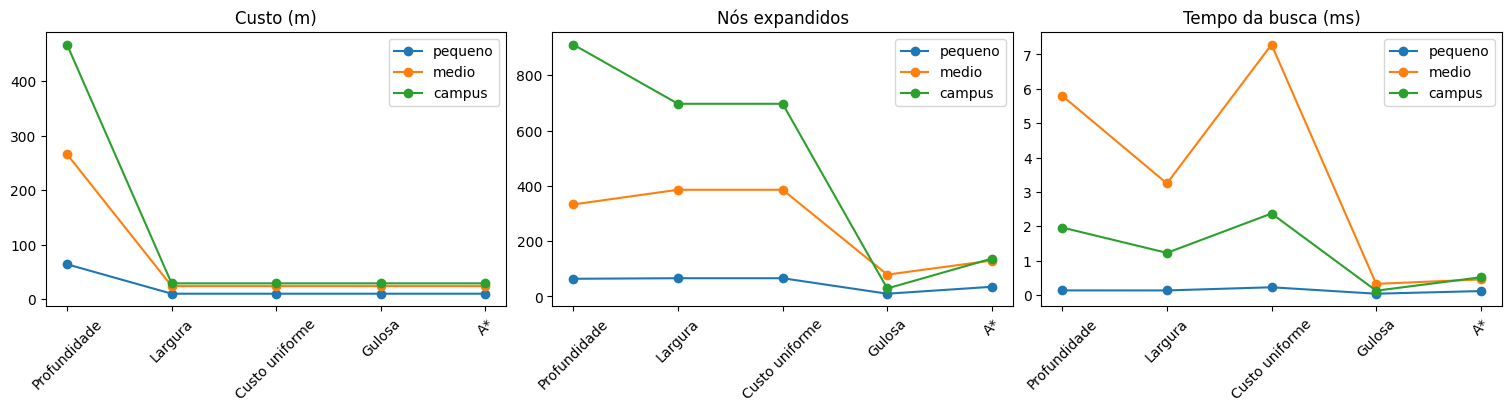

In [3]:
import experimentos_buscas as experimento
import campus_config as cfg
import matplotlib.pyplot as plt

piso = cfg.piso
cenarios = [
    ("pequeno", (-5, 5, -2, 6), "EXT01", "EXT04"),
    ("medio", (-16, 16, -2, 17), "EXT01", "CAN01"),
    ("campus", (piso["x_min"], piso["x_max"],
                piso["y_min"], piso["y_max"]), "EXT01", "H01"),
]
comparacao = []
for nome, limites, origem, destino in cenarios:
    mapa = grade.recorte(limites)
    linhas, _ = experimento.medir(grade, mapa, origem, destino, repeticoes=3)
    comparacao.extend({"mapa": nome, **linha} for linha in linhas)

for linha in comparacao:
    print(f"{linha['mapa']:7} {linha['algoritmo']:14} "
          f"custo={linha['custo_grade_m']:5.0f} m  "
          f"expansões={linha['nos_expandidos']:4}  "
          f"tempo={linha['tempo_mediana_ms']:.3f} ms")

fig, eixos = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for eixo, campo, titulo in zip(
    eixos, ("custo_grade_m", "nos_expandidos", "tempo_mediana_ms"),
    ("Custo (m)", "Nós expandidos", "Tempo da busca (ms)")):
    for nome, *_ in cenarios:
        linhas = [r for r in comparacao if r["mapa"] == nome]
        eixo.plot([r["algoritmo"] for r in linhas], [r[campo] for r in linhas],
                  marker="o", label=nome)
    eixo.set_title(titulo)
    eixo.tick_params(axis="x", labelrotation=45)
    eixo.legend()
plt.show()

## 4. Carregar o Qwen

`transformers` formata a conversa. Na v9, a primeira geração pede uma
decisão em JSON; o Python valida o nome e os argumentos antes de chamar
a ferramenta. A GPU acelera a geração; em CPU o mesmo código funciona
mais devagar. O modelo público não exige token de API neste notebook.

In [4]:
# A instalação é feita dentro do ambiente Python do próprio notebook.
%pip install -q "transformers>=4.45,<5"

In [5]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

NOME_MODELO = "Qwen/Qwen2.5-1.5B-Instruct"
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
tipo = torch.float16 if dispositivo == "cuda" else torch.float32
tokenizador = AutoTokenizer.from_pretrained(NOME_MODELO)
qwen = AutoModelForCausalLM.from_pretrained(NOME_MODELO, dtype=tipo).to(dispositivo)
qwen.eval()  # Inferência: não treinamos os pesos do modelo aqui.
print("Modelo carregado em", dispositivo)

def conversar(mensagens, ferramentas):
    """Gera uma resposta; versões antigas também usam `tools` no template."""
    entrada = tokenizador.apply_chat_template(
        mensagens, tools=ferramentas, add_generation_prompt=True,
        return_tensors="pt", return_dict=True,
    ).to(dispositivo)
    with torch.no_grad():
        saida = qwen.generate(
            **entrada, max_new_tokens=180, do_sample=False,
            pad_token_id=tokenizador.eos_token_id,
        )
    novos = saida[0][entrada["input_ids"].shape[-1]:]
    return tokenizador.decode(novos, skip_special_tokens=True).strip()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo carregado em cpu


## 5. Acompanhar uma pergunta de ponta a ponta

O registro mostra a decisão do modelo, os argumentos e o resultado da
ferramenta. O valor de referência é montado diretamente dos dados do A*.
Se o modelo não chamar a ferramenta, isso aparece como falha observável.

In [6]:
# Este pedido chamou o A* no ensaio local. A bateria abaixo também
# mostra casos em que o mesmo modelo falha ao escolher a ferramenta.
pergunta = "Calcule a distância da Entrada IESB até o Bloco E."
# v9 usa seleção em JSON e impede rotas para locais não citados.
execucao = agente(pergunta, conversar, versao="v9")
print("Pedido:", pergunta)
print("Decisão bruta do Qwen:", execucao["decisao_modelo"])
for chamada in execucao["chamadas"]:
    print("Ferramenta:", chamada["name"], chamada["arguments"])
    print("Referência:", resposta_de_referencia(chamada["resultado"]))
print("Resposta bruta do Qwen:", execucao["resposta_modelo"])
print("Resposta apresentada:", execucao["resposta"])
print("Resposta ajustada pelo código:", execucao.get("resposta_ajustada", False))
print("Erro do ciclo:", execucao["erro"])

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Pedido: Calcule a distância da Entrada IESB até o Bloco E.
Decisão bruta do Qwen: ```json
{
  "name": "calcular_rota",
  "arguments": {
    "origem": "EXT01",
    "destino": "E01"
  }
}
```
Ferramenta: calcular_rota {'origem': 'EXT01', 'destino': 'E01'}
Referência: A*: Entrada IESB → Bloco E; distância total 23.71 m no mapa provisório.
Resposta bruta do Qwen: Distância total entre a Entrada IESB e o Bloco E: **23.71** metro(s) no mapa provisório de 50x30m (antigo).
Resposta apresentada: Distância total entre a Entrada IESB e o Bloco E: **23.71** metro(s) no mapa provisório de 50x30m (antigo).
Resposta ajustada pelo código: False
Erro do ciclo: None


## 6. Avaliar os 15 pedidos definidos antes da execução

`CASOS` contém o pedido, a primeira ferramenta esperada e seus
argumentos. A avaliação automática separa **escolha da ferramenta**,
**argumentos** e **presença do custo correto** na fala bruta. A última
checagem é numérica; o grupo ainda deve ler as respostas para identificar
invenções, recusas inadequadas e erros de linguagem. Uma distância
correta para argumentos errados não resolve o pedido original.

Os casos de fora do domínio esperam recusa sem busca. Se o modelo pedir
`calcular_rota` com um local inexistente, o código devolve erro em vez de
inventar uma rota; registre essa diferença na análise.

In [7]:
from collections import defaultdict

execucoes = {}
avaliacoes = []
for caso in CASOS:
    execucoes[caso["id"]] = agente(caso["pedido"], conversar, versao="v9")
    linha = avaliar_caso(caso, execucoes[caso["id"]])
    avaliacoes.append(linha)
    primeira = execucoes[caso["id"]]["chamadas"][:1]
    print(caso["id"], caso["categoria"],
          "chamada:", [(c["name"], c["arguments"]) for c in primeira],
          "ferramenta:", linha["ferramenta_ok"],
          "argumentos:", linha["argumentos_ok"],
          "fidelidade:", linha["fidelidade"],
          "lista completa:", linha["lista_fiel"],
          "recusa:", linha["recusa_ok"],
          "tipo de erro:", linha["tipo_erro"],
          "tempo (s):", round(linha["segundos"], 2))

categorias = defaultdict(list)
for linha in avaliacoes:
    categorias[linha["categoria"]].append(linha)
print("\nAcerto da primeira ferramenta por categoria:")
for categoria, linhas in categorias.items():
    acertos = sum(linha["ferramenta_ok"] for linha in linhas)
    print(f"{categoria}: {acertos}/{len(linhas)}")
print("Total:", sum(linha["ferramenta_ok"] for linha in avaliacoes),
      "/", len(avaliacoes))
for nome in ("argumentos_ok", "fidelidade", "lista_fiel"):
    aplicaveis = [linha[nome] for linha in avaliacoes if linha[nome] is not None]
    print(nome, sum(aplicaveis), "/", len(aplicaveis))
recusas = [linha["recusa_ok"] for linha in avaliacoes if linha["recusa_ok"] is not None]
print("Recusas fora do domínio:", sum(recusas), "/", len(recusas))

F01 facil chamada: [('calcular_rota', {'origem': 'EXT01', 'destino': 'BB01'})] ferramenta: True argumentos: True fidelidade: True lista completa: None recusa: None tipo de erro: None tempo (s): 61.19
F02 facil chamada: [('calcular_rota', {'origem': 'BB01', 'destino': 'H01'})] ferramenta: True argumentos: True fidelidade: True lista completa: None recusa: None tipo de erro: None tempo (s): 60.97
F03 facil chamada: [('calcular_rota', {'origem': 'EXT04', 'destino': 'CAN01'})] ferramenta: True argumentos: False fidelidade: None lista completa: None recusa: None tipo de erro: argumento_errado tempo (s): 40.98
F04 facil chamada: [('calcular_rota', {'origem': 'EXT01', 'destino': 'E01'})] ferramenta: True argumentos: True fidelidade: True lista completa: None recusa: None tipo de erro: None tempo (s): 49.51
F05 facil chamada: [('calcular_rota', {'origem': 'EXT06', 'destino': 'BB01'})] ferramenta: True argumentos: False fidelidade: None lista completa: None recusa: None tipo de erro: argumento_

In [8]:
# Examine também os erros. A taxa isolada não mostra por que falharam.
for caso in CASOS:
    execucao = execucoes[caso["id"]]
    linha = next(x for x in avaliacoes if x["id"] == caso["id"])
    if linha["tipo_erro"]:
        print("\nCASO", caso["id"], caso["pedido"])
        print("Esperado:", caso["ferramenta"], caso["argumentos"])
        print("Decisão bruta:", execucao["decisao_modelo"])
        print("Chamadas:", [(c["name"], c["arguments"]) for c in execucao["chamadas"]])
        print("Resposta bruta do Qwen:", execucao["resposta_modelo"])
        print("Resposta apresentada:", execucao["resposta"])
        print("Ajustada pelo código:", execucao.get("resposta_ajustada", False))


CASO F03 Como vou do Bloco C à Cantina?
Esperado: calcular_rota {'origem': 'Bloco C', 'destino': 'Cantina'}
Decisão bruta: {
  "name": "calcular_rota",
  "arguments": {
    "origem": "EXT04",
    "destino": "CAN01"
  }
}
Chamadas: [('calcular_rota', {'origem': 'EXT04', 'destino': 'CAN01'})]
Resposta bruta do Qwen: Não há rota confirmada para o bloco C e a cantina. Por favor, verifique se as informações estão corretas.
Resposta apresentada: Os locais da chamada não correspondem aos citados no pedido. Confirme origem e destino.
Ajustada pelo código: True

CASO F05 Rota do Bloco D para a Central de Atendimento, por favor.
Esperado: calcular_rota {'origem': 'Bloco D', 'destino': 'Central de Atendimento'}
Decisão bruta: {
  "name": "calcular_rota",
  "arguments": {
    "origem": "EXT06",
    "destino": "BB01"
  }
}
Chamadas: [('calcular_rota', {'origem': 'EXT06', 'destino': 'BB01'})]
Resposta bruta do Qwen: Não há rota confirmada. Por favor, verifique as informações de origem e destino.
Re